#Tugas Akhir IF5150 - Project 2
Implementasi Model untuk Machine Learning

Kelompok 2
*   23526001 - Matthew Martianus Henry
*   23526019 - M. Ilyas Tri Khaqiqi
*   23526037 - Sandy Pradana










##1. Preprocessing
Import package, memuat data, EDA, cleaning data, select feature, dan Split data

###1.1 Import Package

In [300]:
import pandas as pd
import numpy as np

#Untuk Grafik
import matplotlib.pyplot as plt
import seaborn as sns

###1.2 Memuat data

In [301]:
url = "https://sandypradana886.github.io/if5150/dataset/"
train = pd.read_csv(url + "train.csv")
test = pd.read_csv(url + "test.csv")
sample_submission = pd.read_csv(url + "sample_submission.csv")
var_desc = pd.read_csv(url + "variables_description.csv")

In [302]:
var_desc

,name,description
0,Marital Status,1 - single 2 - married 3 - widower 4 - divorce...
1,Application mode,1 - 1st phase - general contingent 2 - Ordinan...
2,Application order,Application order (between 0 - first choice; a...
3,Course,33 - Biofuel Production Technologies 171 - Ani...
4,Daytime/evening attendance,1 - daytime 0 - evening
5,Previous qualification,1 - Secondary education 2 - Higher education -...
6,Previous qualification (grade),Grade of previous qualification (between 0 and...
7,Nacionality,1 - Portuguese; 2 - German; 6 - Spanish; 11 - ...
8,Mother's qualification,1 - Secondary Education - 12th Year of Schooli...
9,Father's qualification,1 - Secondary Education - 12th Year of Schooli...


In [303]:
train.shape

(3096, 38)

In [304]:
test.shape

(1328, 37)

###1.3 Explorasi Data Train

####1.3.1 Preview Data

In [305]:
print("5 baris pertama:")
display(train.head())
print("5 baris terakhir:")
display(train.tail())

5 baris pertama:


,Student_ID,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,3743,1,17,1,9670,1,1,118.0,1,19,...,0,6,6,6,14.000000,0,12.4,0.5,1.79,Graduate
1,3540,1,1,1,9070,1,1,139.0,1,1,...,0,6,7,6,12.166667,1,16.2,0.3,-0.92,Graduate
2,1118,1,1,1,9500,1,1,138.0,1,38,...,0,8,8,7,13.571429,0,13.9,-0.3,0.79,Graduate
3,791,1,17,1,9773,1,1,138.0,1,1,...,0,6,6,6,13.833333,0,11.1,0.6,2.02,Graduate
4,4381,1,7,1,9500,1,2,140.0,1,38,...,0,8,14,4,11.325000,1,12.7,3.7,-1.70,Dropout


5 baris terakhir:


,Student_ID,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
3091,898,1,43,1,9070,1,39,130.0,1,19,...,5,12,12,11,12.545455,0,15.5,2.8,-4.06,Graduate
3092,1998,1,17,1,9773,1,1,121.0,1,37,...,0,6,6,6,13.333333,0,13.9,-0.3,0.79,Graduate
3093,72,1,17,1,9500,1,1,150.0,1,37,...,0,8,8,8,13.750000,0,13.9,-0.3,0.79,Graduate
3094,968,1,39,1,9003,1,12,133.1,1,37,...,0,6,6,0,0.000000,0,13.9,-0.3,0.79,Dropout
3095,3303,1,17,1,9500,1,1,128.0,1,37,...,0,8,8,8,13.313750,0,15.5,2.8,-4.06,Graduate


####1.3.2 Statistik Deskriptif

In [306]:
print("Jumlah baris  :", train.shape[0])
print("Jumlah kolom  :", train.shape[1])

train.describe().T

Jumlah baris  : 3096
Jumlah kolom  : 38


,count,mean,std,min,25%,50%,75%,max
Student_ID,3096.0,2201.759690,1275.008676,1.00,1102.75,2212.000000,3303.750000,4424.000000
Marital status,3096.0,1.166021,0.573701,1.00,1.00,1.000000,1.000000,6.000000
Application mode,3096.0,18.372416,17.456612,1.00,1.00,17.000000,39.000000,57.000000
Application order,3096.0,1.717700,1.292362,0.00,1.00,1.000000,2.000000,9.000000
Course,3096.0,8832.330749,2116.515003,33.00,9085.00,9238.000000,9556.000000,9991.000000
Daytime/evening attendance\t,3096.0,0.894380,0.307400,0.00,1.00,1.000000,1.000000,1.000000
Previous qualification,3096.0,4.672804,10.387415,1.00,1.00,1.000000,1.000000,43.000000
Previous qualification (grade),3096.0,132.762435,13.137942,95.00,125.00,133.100000,140.000000,190.000000
Nacionality,3096.0,1.797158,6.781964,1.00,1.00,1.000000,1.000000,108.000000
Mother's qualification,3096.0,19.361111,15.568871,1.00,2.00,19.000000,37.000000,44.000000


####1.3.3 Distribusi Target

Distribusi target: {'Graduate': 0.499, 'Dropout': 0.321, 'Enrolled': 0.18}


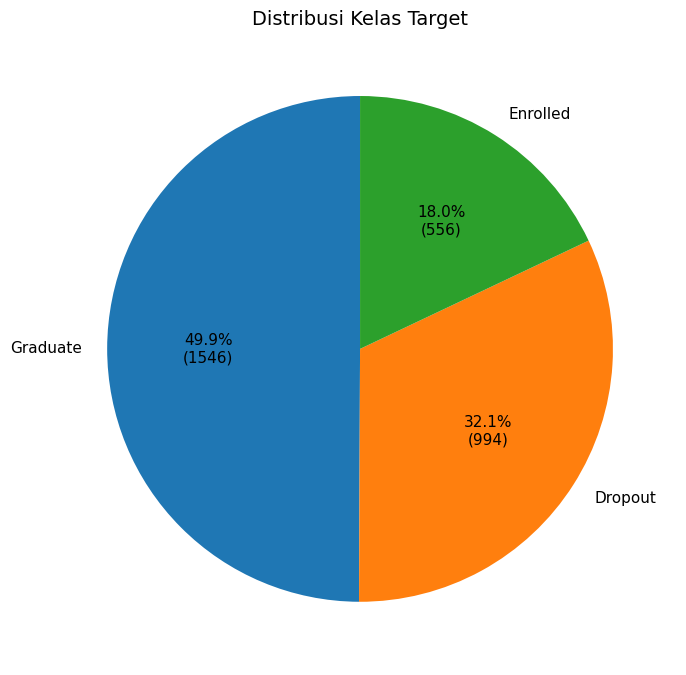

In [307]:
print("Distribusi target:", train["Target"].value_counts(normalize=True).round(3).to_dict())

target_dist = train["Target"].value_counts()


##Visualisasi Data Target
target_dist = train["Target"].value_counts()
plt.figure(figsize=(7,7))
plt.pie(
    target_dist,
    labels=target_dist.index,
    autopct=lambda p: f"{p:.1f}%\n({round(p/100*target_dist.sum())})",
    startangle=90,
    textprops={'fontsize':11}
)
plt.title("Distribusi Kelas Target", fontsize=14)
plt.tight_layout()
plt.show()

#### 1.3.4 Persiapan EDA lanjutan

Bagian ini bekerja dengan salinan `train` dan `test`, jadi data asli untuk preprocessing di bawah tidak ikut berubah.

Jenis setiap kolom kami tentukan dari kamus data (`var_desc`), bukan dari tipe data pandas. Alasannya, banyak kolom yang isinya angka sebenarnya adalah kode kategori. Contohnya `Course = 9119` artinya Informatics Engineering. Angka 9119 itu tidak lebih besar atau lebih kecil dari kode prodi lain, jadi tidak boleh dihitung seperti angka biasa.

Selain grafik, hubungan tiap fitur dengan target juga kami ukur dengan uji statistik dan *effect size*, supaya bisa dibandingkan secara angka.

In [308]:
import re
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier as SkRandomForestEDA
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import StratifiedKFold as SkStratifiedKFoldEDA, cross_val_score as sk_cross_val_score_eda

EDA_CLASSES = ["Dropout", "Enrolled", "Graduate"]
# Warna kelas bermakna: merah = risiko dropout, kuning = masih kuliah, hijau = lulus.
EDA_COLORS = {"Dropout": "#b5473a", "Enrolled": "#d49a2a", "Graduate": "#2f7d64"}


def eda_clean_names(df):
    df = df.copy()
    df.columns = [c.strip() for c in df.columns]
    return df.rename(columns={"Nacionality": "Nationality"})


def sem(s, f):
    return f"Curricular units {s} sem ({f})"


def short(c):
    return c.replace("Curricular units ", "CU ").replace(" sem ", " ")


eda = eda_clean_names(train)
eda_test = eda_clean_names(test)
EDA_CAT = ["Marital status", "Application mode", "Course", "Previous qualification", "Nationality",
           "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
EDA_BIN = ["Daytime/evening attendance", "Displaced", "Educational special needs", "Debtor",
           "Tuition fees up to date", "Gender", "Scholarship holder", "International"]
EDA_SEM = ["credited", "enrolled", "evaluations", "approved", "grade", "without evaluations"]
EDA_NUM = (["Application order", "Previous qualification (grade)", "Admission grade", "Age at enrollment"]
           + [sem(s, f) for s in ("1st", "2nd") for f in EDA_SEM] + ["Unemployment rate", "Inflation rate", "GDP"])
EDA_FEATURES = EDA_NUM + EDA_BIN + EDA_CAT

# Kamus kode -> label dari variables_description.csv, misalnya {"Course": {9119: "Informatics Engineering", ...}}.
_code_pat = re.compile(r"(?:^|(?<=\s)|(?<=;))(\d+)\s+-\s+")
eda_labels = {}
for _, r in var_desc.iterrows():
    parts = _code_pat.split(str(r["description"]))
    if len(parts) >= 4:
        name = {"Marital Status": "Marital status", "Nacionality": "Nationality"}.get(r["name"].strip(), r["name"].strip())
        eda_labels[name] = {int(parts[i]): parts[i + 1].strip().rstrip(";").strip() for i in range(1, len(parts) - 1, 2)}

role = {**{c: "numerik" for c in EDA_NUM}, **{c: "biner" for c in EDA_BIN}, **{c: "kategorikal (kode)" for c in EDA_CAT}}
schema = pd.DataFrame({"peran": pd.Series(role), "dtype": eda.dtypes.astype(str), "n_unik": eda.nunique(),
                       "missing": eda.isna().sum(), "min": eda.min(numeric_only=True), "max": eda.max(numeric_only=True)}).loc[EDA_FEATURES]
display(schema)
print("Kolom per peran:", schema["peran"].value_counts().to_dict())

,peran,dtype,n_unik,missing,min,max
Application order,numerik,int64,8,0,0.00,9.000000
Previous qualification (grade),numerik,float64,96,0,95.00,190.000000
Admission grade,numerik,float64,576,0,95.00,190.000000
Age at enrollment,numerik,int64,46,0,17.00,70.000000
Curricular units 1st sem (credited),numerik,int64,21,0,0.00,20.000000
Curricular units 1st sem (enrolled),numerik,int64,22,0,0.00,26.000000
Curricular units 1st sem (evaluations),numerik,int64,34,0,0.00,45.000000
Curricular units 1st sem (approved),numerik,int64,22,0,0.00,26.000000
Curricular units 1st sem (grade),numerik,float64,612,0,0.00,18.875000
Curricular units 1st sem (without evaluations),numerik,int64,11,0,0.00,12.000000


Kolom per peran: {'numerik': 19, 'kategorikal (kode)': 9, 'biner': 8}


#### 1.3.5 Audit kualitas data

In [309]:
print("Nama kolom dengan spasi/tab tersembunyi:", [repr(c) for c in train.columns if c != c.strip()])
print("Kolom dengan ejaan tidak baku       :", [c for c in train.columns if "Nacionality" in c])
print("Total sel kosong (train / test)     :", int(train.isna().sum().sum()), "/", int(test.isna().sum().sum()))
print("Baris duplikat (fitur + target)     :", int(eda.duplicated(subset=EDA_FEATURES + ["Target"]).sum()))
print("Fitur sama tetapi target berbeda    :", int(eda.duplicated(subset=EDA_FEATURES, keep=False).sum()))
print("Student_ID ganda / muncul di test   :", int(eda["Student_ID"].duplicated().sum()), "/", int(eda["Student_ID"].isin(eda_test["Student_ID"]).sum()))

ranges = {"Application order": (0, 9), "Previous qualification (grade)": (0, 200), "Admission grade": (0, 200),
          "Age at enrollment": (15, 100), sem("1st", "grade"): (0, 20), sem("2nd", "grade"): (0, 20)}
ranges.update({sem(s, f): (0, np.inf) for s in ("1st", "2nd") for f in EDA_SEM if f != "grade"})
dom = {c: (int(((eda[c] < lo) | (eda[c] > hi)).sum()), int(((eda_test[c] < lo) | (eda_test[c] > hi)).sum())) for c, (lo, hi) in ranges.items()}
dom.update({c: (int((~eda[c].isin([0, 1])).sum()), int((~eda_test[c].isin([0, 1])).sum())) for c in EDA_BIN})
print("Pelanggaran rentang domain kamus data (train, test):", tuple(map(sum, zip(*dom.values()))))


def logic_checks(d):
    out = {}
    for s in ("1st", "2nd"):
        e, a, cr, ev, g, wo = (d[sem(s, f)] for f in ("enrolled", "approved", "credited", "evaluations", "grade", "without evaluations"))
        out[f"{s}: approved <= enrolled"] = int((a > e).sum())
        out[f"{s}: credited <= enrolled"] = int((cr > e).sum())
        out[f"{s}: without evaluations <= enrolled"] = int((wo > e).sum())
        out[f"{s}: approved <= evaluations"] = int((a > ev).sum())
        out[f"{s}: grade = 0 tepat ketika approved = 0"] = int(((a > 0) & (g == 0)).sum() + ((a == 0) & (g > 0)).sum())
        out[f"{s}: enrolled > 0 tetapi evaluations = 0"] = int(((e > 0) & (ev == 0)).sum())
    return out


display(pd.DataFrame({"train": logic_checks(eda), "test": logic_checks(eda_test)}))
wo2, en2 = sem("2nd", "without evaluations"), sem("2nd", "enrolled")
display(eda.loc[eda[wo2] > eda[en2], ["Student_ID", en2, sem("2nd", "evaluations"), sem("2nd", "approved"), wo2, "Target"]])

codes = pd.DataFrame([{"kolom": c, "kode_di_kamus": len(eda_labels.get(c, {})), "kode_di_train": eda[c].nunique(),
                       "tidak_ada_di_kamus": sorted(map(int, (set(eda[c]) | set(eda_test[c])) - set(eda_labels.get(c, {})))),
                       "hanya_di_test": sorted(map(int, set(eda_test[c]) - set(eda[c]))),
                       "baris_test_terdampak": int(eda_test[c].isin(set(eda_test[c]) - set(eda[c])).sum())} for c in EDA_CAT])
display(codes)

Nama kolom dengan spasi/tab tersembunyi: ["'Daytime/evening attendance\\t'"]
Kolom dengan ejaan tidak baku       : ['Nacionality']
Total sel kosong (train / test)     : 0 / 0
Baris duplikat (fitur + target)     : 0
Fitur sama tetapi target berbeda    : 0
Student_ID ganda / muncul di test   : 0 / 0
Pelanggaran rentang domain kamus data (train, test): (0, 0)


,train,test
1st: approved <= enrolled,0,0
1st: credited <= enrolled,0,0
1st: without evaluations <= enrolled,0,0
1st: approved <= evaluations,0,0
1st: grade = 0 tepat ketika approved = 0,0,0
1st: enrolled > 0 tetapi evaluations = 0,124,45
2nd: approved <= enrolled,0,0
2nd: credited <= enrolled,0,0
2nd: without evaluations <= enrolled,1,2
2nd: approved <= evaluations,0,0


,Student_ID,Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (without evaluations),Target
2634,534,6,12,0,12,Dropout


,kolom,kode_di_kamus,kode_di_train,tidak_ada_di_kamus,hanya_di_test,baris_test_terdampak
0,Marital status,6,6,[],[],0
1,Application mode,18,18,[],[],0
2,Course,17,17,[],[],0
3,Previous qualification,17,17,[],[],0
4,Nationality,21,17,[],"[17, 25, 32, 109]",5
5,Mother's qualification,29,28,[],[27],1
6,Father's qualification,34,32,[],"[13, 33]",2
7,Mother's occupation,32,31,[],[125],1
8,Father's occupation,46,40,[],"[114, 121, 124, 132, 134, 174]",6


**Catatan**

* Hanya ada satu aturan yang dilanggar, yaitu `without evaluations <= enrolled` di semester 2. Pelanggarannya ada di 1 baris train dan 2 baris test. Misalnya `Student_ID` 534 tercatat mengambil 6 mata kuliah, tapi 12 mata kuliah tanpa evaluasi. Ini jelas salah catat. Kalau mau diperbaiki, cukup sel itu saja yang dikosongkan lalu diisi median dari train. Baris lainnya tetap bisa dipakai.
* Ada juga mahasiswa yang mengambil mata kuliah tapi tidak punya evaluasi sama sekali (124 dan 156 baris di train). Ini bukan salah catat. Mahasiswa seperti ini mendaftar kelas tapi tidak ikut ujian, dan itu wajar dibaca sebagai tanda awal dropout. Baris ini tetap dipakai karena justru berguna untuk prediksi.
* Semua kode di train dan test ada di kamus data, jadi tidak ada kode yang tidak valid.
* Ada 5 kolom di test yang memuat kode yang tidak pernah muncul di train, totalnya 15 baris (paling banyak di `Father's occupation`). Karena itu encoder harus bisa menangani kode baru, misalnya dengan memasukkannya ke kategori `other`, supaya prediksi tidak error. Kategori yang sangat jarang di train (1 sampai 2 baris) juga sebaiknya digabung ke `other`, karena kolom one-hot untuk kategori sekecil itu hampir tidak membawa informasi.

#### 1.3.6 Target: ketidakseimbangan dan baseline

In [318]:
eda_counts = eda["Target"].value_counts().loc[EDA_CLASSES]
eda_share = eda_counts / eda_counts.sum()
print(f"Rasio ketidakseimbangan (mayoritas : minoritas) = {eda_counts.max() / eda_counts.min():.2f} : 1")
print(f"Akurasi baseline (selalu menebak '{eda_counts.idxmax()}') = {eda_share.max():.4f}")
print(f"Macro-F1 baseline yang sama = {(2 * eda_share.max() / (1 + eda_share.max())) / 3:.4f}")

Rasio ketidakseimbangan (mayoritas : minoritas) = 2.78 : 1
Akurasi baseline (selalu menebak 'Graduate') = 0.4994
Macro-F1 baseline yang sama = 0.2220


**Catatan**

* Jumlah tiap kelas tidak seimbang. Graduate 49,9%, Dropout 32,1%, dan Enrolled hanya 18,0%. Kelas terbesar 2,78 kali kelas terkecil.
* Kalau model selalu menebak Graduate, akurasinya sudah 0,499, padahal model itu tidak belajar apa pun. Macro-F1 model seperti ini hanya 0,222. Karena itu kami memakai macro-F1 sebagai ukuran utama saat memilih hyperparameter, membuat split secara stratified, dan mencoba beberapa cara menangani ketidakseimbangan (class weight dan SMOTE).

#### 1.3.7 Fitur numerik terhadap target

Fitur numerik di data ini tidak berdistribusi normal (miring dan banyak nilai nol), jadi kami memakai uji Kruskal-Wallis yang tidak butuh asumsi normal.

Besar efeknya diukur dengan epsilon-squared, ε² = H / (n − 1). Sebagai patokan, sekitar 0,01 berarti efek kecil, 0,08 sedang, dan 0,26 ke atas besar (Tomczak & Tomczak, 2014). Dengan 3.096 baris data, p-value hampir selalu kecil, jadi untuk membandingkan fitur kami melihat ε², bukan p-value.

Tabel di bawah juga memuat beberapa fitur turunan berupa rasio, untuk melihat apakah rasio lebih berguna daripada angka mentahnya.

,fitur,turunan,H,p_value,epsilon2,median_Dropout,median_Enrolled,median_Graduate,kekuatan
0,approval_rate_2nd,True,1531.293689,0.000000e+00,0.494764,0.000000,0.714286,1.000000,besar
1,eval_success_2nd,True,1415.486532,4.275679e-308,0.457346,0.000000,0.444444,0.857143,besar
2,CU 2nd (approved),False,1293.484116,1.328902e-281,0.417927,0.000000,4.000000,6.000000,besar
3,approval_rate_1st,True,1245.020869,4.437652e-271,0.402268,0.333333,0.800000,1.000000,besar
4,approved_total,True,1234.370360,9.117631e-269,0.398827,3.000000,9.000000,12.000000,besar
5,eval_success_1st,True,1156.052878,9.253523e-252,0.373523,0.184659,0.500000,0.857143,besar
6,CU 1st (approved),False,1038.951736,2.480259e-226,0.335687,2.000000,5.000000,6.000000,besar
7,grade_mean,True,1029.563719,2.710685e-224,0.332654,6.375000,11.941667,12.991193,besar
8,CU 2nd (grade),False,954.039705,6.806289e-208,0.308252,0.000000,11.990000,13.000000,besar
9,CU 1st (grade),False,784.359282,4.770303e-171,0.253428,10.800000,12.000000,13.000000,sedang


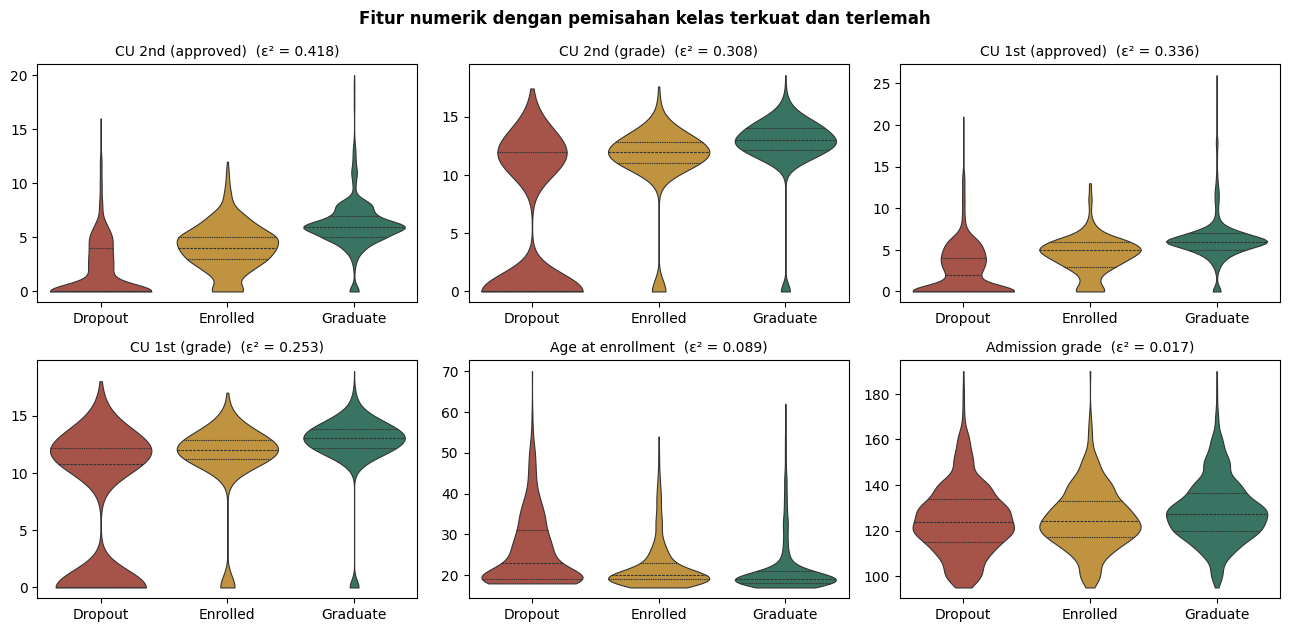

In [310]:
def eda_add_features(d):
    d = d.copy()
    for s in ("1st", "2nd"):
        e, a, v = d[sem(s, "enrolled")], d[sem(s, "approved")], d[sem(s, "evaluations")]
        d[f"approval_rate_{s}"] = np.where(e > 0, a / e.where(e > 0), 0.0)
        d[f"eval_success_{s}"] = np.where(v > 0, a / v.where(v > 0), 0.0)
    d["approved_total"] = d[sem("1st", "approved")] + d[sem("2nd", "approved")]
    d["grade_mean"] = (d[sem("1st", "grade")] + d[sem("2nd", "grade")]) / 2
    d["grade_delta"] = d[sem("2nd", "grade")] - d[sem("1st", "grade")]
    d["no_academic_record"] = ((d[sem("1st", "enrolled")] == 0) & (d[sem("2nd", "enrolled")] == 0)).astype(float)
    return d


EDA_ENG = ["approval_rate_1st", "approval_rate_2nd", "eval_success_1st", "eval_success_2nd",
           "approved_total", "grade_mean", "grade_delta", "no_academic_record"]
eda_x = eda_add_features(eda)
rows = []
for c in EDA_NUM + EDA_ENG:
    groups = [eda_x.loc[eda_x["Target"] == k, c] for k in EDA_CLASSES]
    H, p = stats.kruskal(*groups)
    rows.append({"fitur": short(c), "turunan": c in EDA_ENG, "H": H, "p_value": p, "epsilon2": H / (len(eda_x) - 1),
                 **{f"median_{k}": g.median() for k, g in zip(EDA_CLASSES, groups)}})
kw = pd.DataFrame(rows).sort_values("epsilon2", ascending=False).reset_index(drop=True)
kw["kekuatan"] = pd.cut(kw["epsilon2"], [-1, 0.01, 0.08, 0.26, 1], labels=["sangat kecil", "kecil", "sedang", "besar"])
display(kw)

fig, axes = plt.subplots(2, 3, figsize=(13, 6.4))
for ax, c in zip(axes.ravel(), [sem("2nd", "approved"), sem("2nd", "grade"), sem("1st", "approved"),
                                sem("1st", "grade"), "Age at enrollment", "Admission grade"]):
    sns.violinplot(data=eda, x="Target", y=c, order=EDA_CLASSES, hue="Target", palette=EDA_COLORS,
                   legend=False, ax=ax, cut=0, inner="quartile", linewidth=0.8)
    ax.set_title(f"{short(c)}  (ε² = {kw.loc[kw['fitur'] == short(c), 'epsilon2'].iloc[0]:.3f})", fontsize=10)
    ax.set_xlabel(""); ax.set_ylabel("")
fig.suptitle("Fitur numerik dengan pemisahan kelas terkuat dan terlemah", fontweight="bold")
fig.tight_layout()
plt.show()

**Catatan**

* Fitur dengan efek terbesar adalah rasio kelulusan mata kuliah semester 2 (`approval_rate_2nd`, ε² = 0,495). Enam fitur teratas kebanyakan fitur turunan. Artinya, rasio (lulus dibagi diambil, atau lulus dibagi dievaluasi) lebih informatif daripada jumlah mentah, karena beban studi tiap mahasiswa berbeda.
* Median mata kuliah yang lulus di semester 2: Dropout 0, Enrolled 4, Graduate 6.
* Umur saat masuk berpengaruh sedang (ε² = 0,089). Median umur mahasiswa Dropout 23 tahun, sedangkan Graduate 19 tahun.
* Nilai masuk dan nilai pendidikan sebelumnya pengaruhnya kecil (ε² sekitar 0,016). Jadi prestasi sebelum kuliah jauh kurang berguna untuk prediksi dibanding prestasi di tahun pertama kuliah.
* Nilai-nilai mahasiswa Enrolled berada di antara Dropout dan Graduate, dan lebih dekat ke Graduate. Dari sini sudah terlihat bahwa Enrolled akan jadi kelas yang paling sulit ditebak.

#### 1.3.8 Fitur kategorikal dan biner terhadap target

Untuk fitur kategorikal kami memakai uji chi-square dan Cramér's V. Cramér's V yang dipakai sudah dikoreksi bias (Bergsma, 2013), karena beberapa kolom punya banyak kategori yang jarang muncul. Sebelum diuji, kategori yang muncul kurang dari 10 kali digabung menjadi `other`.

,fitur,jenis,n_kategori,chi2,dof,p_value,cramers_v
0,Tuition fees up to date,biner,2,585.149492,2,8.637784e-128,0.434070
1,Scholarship holder,biner,2,297.783990,2,2.172843e-65,0.309141
2,Debtor,biner,2,200.249635,2,3.283555e-44,0.253090
3,Course,kategorikal,17,399.233196,32,5.343184e-65,0.243607
4,Application mode,kategorikal,18,360.799556,26,1.195583e-60,0.232601
5,Gender,biner,2,159.147450,2,2.764205e-35,0.225332
6,Mother's occupation,kategorikal,31,188.554528,26,1.339151e-26,0.162074
7,Father's occupation,kategorikal,40,156.583890,26,1.299033e-20,0.145263
8,Previous qualification,kategorikal,17,141.077383,16,4.432599e-22,0.142169
9,Father's qualification,kategorikal,32,138.008135,22,8.466261e-19,0.136917


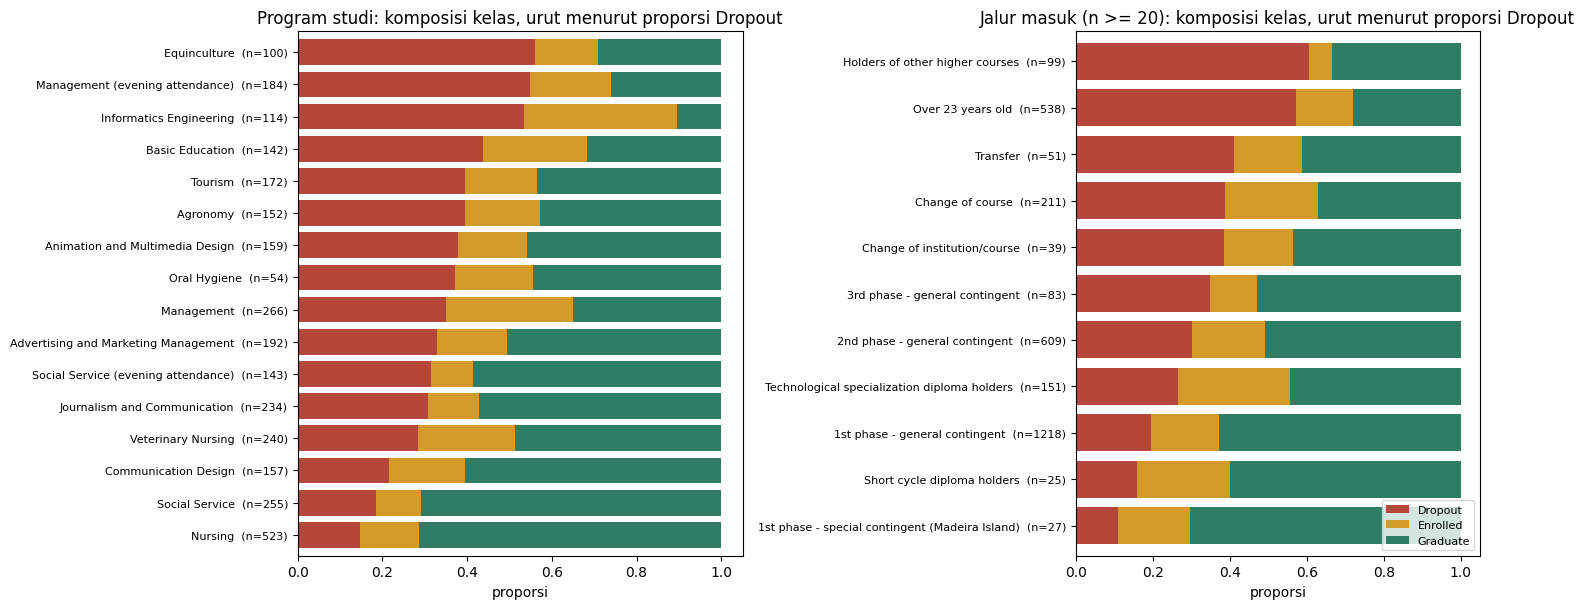

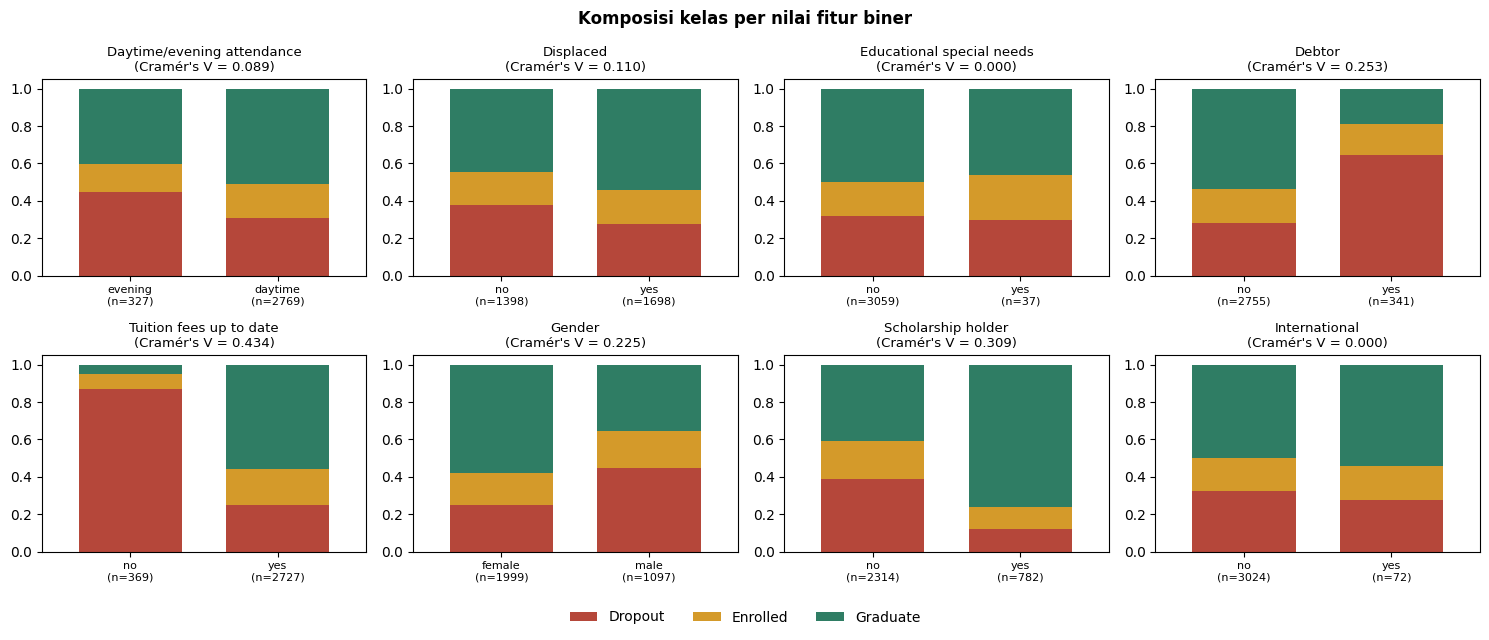

In [311]:
def cramers_v(x, y):
    t = pd.crosstab(x, y)
    chi2, p, dof, _ = stats.chi2_contingency(t, correction=False)
    n = t.to_numpy().sum(); r, k = t.shape
    phi2 = max(0.0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return chi2, p, dof, np.sqrt(phi2 / max(1e-12, min(kc - 1, rc - 1)))


rows = []
for c in EDA_CAT + EDA_BIN:
    x = eda[c].where(eda[c].map(eda[c].value_counts()) >= 10, -1) if c in EDA_CAT else eda[c]
    chi2, p, dof, v = cramers_v(x, eda["Target"])
    rows.append({"fitur": c, "jenis": "kategorikal" if c in EDA_CAT else "biner", "n_kategori": eda[c].nunique(),
                 "chi2": chi2, "dof": dof, "p_value": p, "cramers_v": v})
cv_table = pd.DataFrame(rows).sort_values("cramers_v", ascending=False).reset_index(drop=True)
display(cv_table)


def rate_table(col, min_n=20):
    t = pd.crosstab(eda[col], eda["Target"])
    t = t[t.sum(axis=1) >= min_n]
    share = t.div(t.sum(axis=1), axis=0)[EDA_CLASSES]
    share.index = [f"{eda_labels.get(col, {}).get(int(i), i)}  (n={t.loc[i].sum()})" for i in share.index]
    return share.sort_values("Dropout")


fig, axes = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={"width_ratios": [1.1, 1]})
for ax, col, title in ((axes[0], "Course", "Program studi"), (axes[1], "Application mode", "Jalur masuk (n >= 20)")):
    rate_table(col).plot(kind="barh", stacked=True, ax=ax, color=[EDA_COLORS[c] for c in EDA_CLASSES], width=0.8, legend=False)
    ax.set_title(f"{title}: komposisi kelas, urut menurut proporsi Dropout")
    ax.set_xlabel("proporsi"); ax.tick_params(axis="y", labelsize=8)
axes[1].legend(EDA_CLASSES, loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, c in zip(axes.ravel(), EDA_BIN):
    share = pd.crosstab(eda[c], eda["Target"], normalize="index")[EDA_CLASSES]
    n = eda[c].value_counts().sort_index()
    share.index = [f"{eda_labels.get(c, {}).get(int(i), i)}\n(n={n.loc[i]})" for i in share.index]
    share.plot(kind="bar", stacked=True, ax=ax, color=[EDA_COLORS[k] for k in EDA_CLASSES], legend=False, width=0.7)
    ax.set_title(f"{c}\n(Cramér's V = {cv_table.loc[cv_table['fitur'] == c, 'cramers_v'].iloc[0]:.3f})", fontsize=9.5)
    ax.tick_params(axis="x", rotation=0, labelsize=8); ax.set_xlabel("")
fig.suptitle("Komposisi kelas per nilai fitur biner", fontweight="bold")
fig.tight_layout()
fig.legend(EDA_CLASSES, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=3, frameon=False)
plt.show()

**Catatan**

* Hubungan paling kuat datang dari faktor keuangan: `Tuition fees up to date` (V = 0,434), `Scholarship holder` (0,309), dan `Debtor` (0,253). Sekitar 87% mahasiswa yang menunggak SPP akhirnya Dropout.
* Program studi juga berpengaruh besar (V = 0,244). Persentase Dropout berkisar dari sekitar 15% (Nursing, n = 523) sampai sekitar 56% (Equinculture). Informatics Engineering punya Dropout tinggi dan sangat sedikit yang Graduate.
* Jalur masuk (V = 0,233): jalur `Over 23 years old` (n = 538) dan `Holders of other higher courses` punya Dropout sekitar 57 sampai 61%, sedangkan jalur reguler `1st phase - general contingent` (n = 1.218) sekitar 20%.
* `Gender` berpengaruh sedang (V = 0,225). Persentase Dropout mahasiswa laki-laki lebih tinggi.
* `Nationality`, `Educational special needs`, dan `International` hampir tidak berhubungan dengan target (V ≈ 0, p > 0,3), jadi ketiganya bisa dibuang saat seleksi fitur.
* `Course` dan `Application mode` tetap dipakai, tapi harus di-one-hot karena kodenya tidak punya urutan.

#### 1.3.9 Korelasi dan multikolinearitas

Kami memakai korelasi Spearman karena tidak terganggu distribusi yang miring. Untuk multikolinearitas kami memakai Variance Inflation Factor, VIF_j = 1 / (1 − R²_j). Kalau VIF di atas 10, fitur itu sangat bisa ditebak dari fitur lain, dan koefisien Logistic Regression jadi tidak stabil.

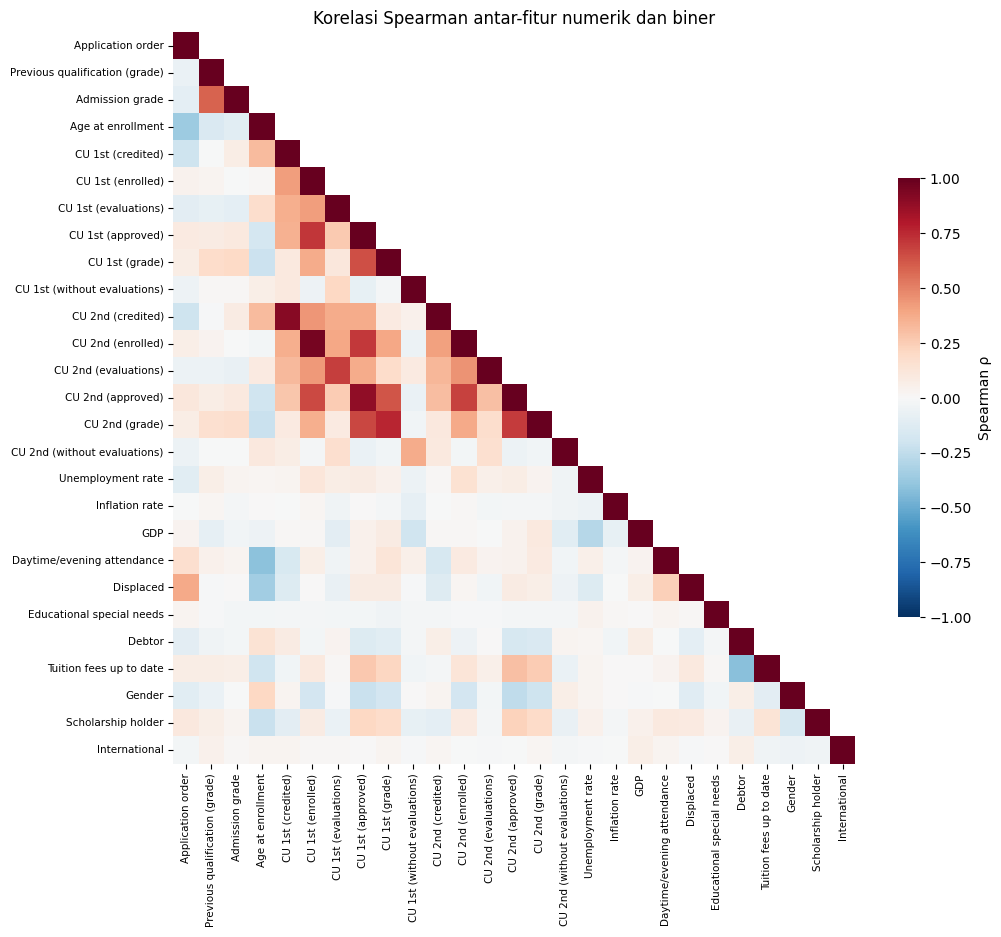

,fitur A,fitur B,rho
2,CU 1st (enrolled),CU 2nd (enrolled),0.960528
0,CU 1st (credited),CU 2nd (credited),0.912448
4,CU 1st (approved),CU 2nd (approved),0.889069
5,CU 1st (grade),CU 2nd (grade),0.762221
1,CU 1st (enrolled),CU 1st (approved),0.712918
3,CU 1st (approved),CU 2nd (enrolled),0.710648


,VIF
CU 1st (enrolled),23.597815
CU 2nd (enrolled),16.634531
CU 1st (credited),16.600709
CU 2nd (credited),13.609872
CU 1st (approved),12.727481
CU 2nd (approved),10.089987
CU 2nd (grade),5.524868
CU 1st (grade),5.174360
CU 1st (evaluations),3.917609
CU 2nd (evaluations),3.325696


In [312]:
sp = eda[EDA_NUM + EDA_BIN].corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9.5))
sns.heatmap(sp, mask=np.triu(np.ones_like(sp, dtype=bool), k=1), cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax,
            xticklabels=[short(c) for c in sp.columns], yticklabels=[short(c) for c in sp.columns], cbar_kws={"shrink": 0.6, "label": "Spearman ρ"})
ax.tick_params(labelsize=7.5)
ax.set_title("Korelasi Spearman antar-fitur numerik dan biner")
plt.show()
cols = list(sp.columns)
display(pd.DataFrame([(short(a), short(b), sp.loc[a, b]) for i, a in enumerate(cols) for b in cols[i + 1:] if abs(sp.loc[a, b]) >= 0.7],
                     columns=["fitur A", "fitur B", "rho"]).sort_values("rho", key=abs, ascending=False))

Z = (eda[EDA_NUM] - eda[EDA_NUM].mean()) / eda[EDA_NUM].std(ddof=0)
vif = {}
for c in Z.columns:
    A = np.column_stack([np.ones(len(Z)), Z.drop(columns=c).to_numpy()])
    beta, *_ = np.linalg.lstsq(A, Z[c].to_numpy(), rcond=None)
    r2 = 1 - np.sum((Z[c].to_numpy() - A @ beta) ** 2) / np.sum((Z[c].to_numpy() - Z[c].mean()) ** 2)
    vif[short(c)] = 1 / max(1e-12, 1 - r2)
display(pd.Series(vif).sort_values(ascending=False).to_frame("VIF").head(10))

**Catatan**

* Fitur semester 1 dan semester 2 sangat mirip satu sama lain: `enrolled` ρ = 0,96, `credited` 0,91, `approved` 0,89, `grade` 0,76.
* VIF untuk `enrolled`, `credited`, dan `approved` di atas 10 (paling tinggi 23,6), jadi multikolinearitasnya kuat.
* Dampaknya ke Logistic Regression: koefisien fitur yang saling mirip jadi tidak stabil dan susah dibaca. Cara mengatasinya adalah regularisasi L2 dan membuang fitur yang isinya dobel.
* Dampaknya ke KNN: fitur yang isinya dobel ikut dihitung dua kali saat menghitung jarak, sehingga informasi beban studi jadi terlalu berat. Seleksi fitur membantu mengurangi masalah ini.

#### 1.3.10 Mutual information dengan target

Mutual information (MI) bisa menangkap hubungan yang tidak lurus (non-linear) dan bisa dipakai untuk fitur kategorikal (Kraskov dkk., 2004; Ross, 2014). Hasil estimasinya agak berubah-ubah tiap kali dijalankan, jadi kami ambil rata-rata dari 5 seed.

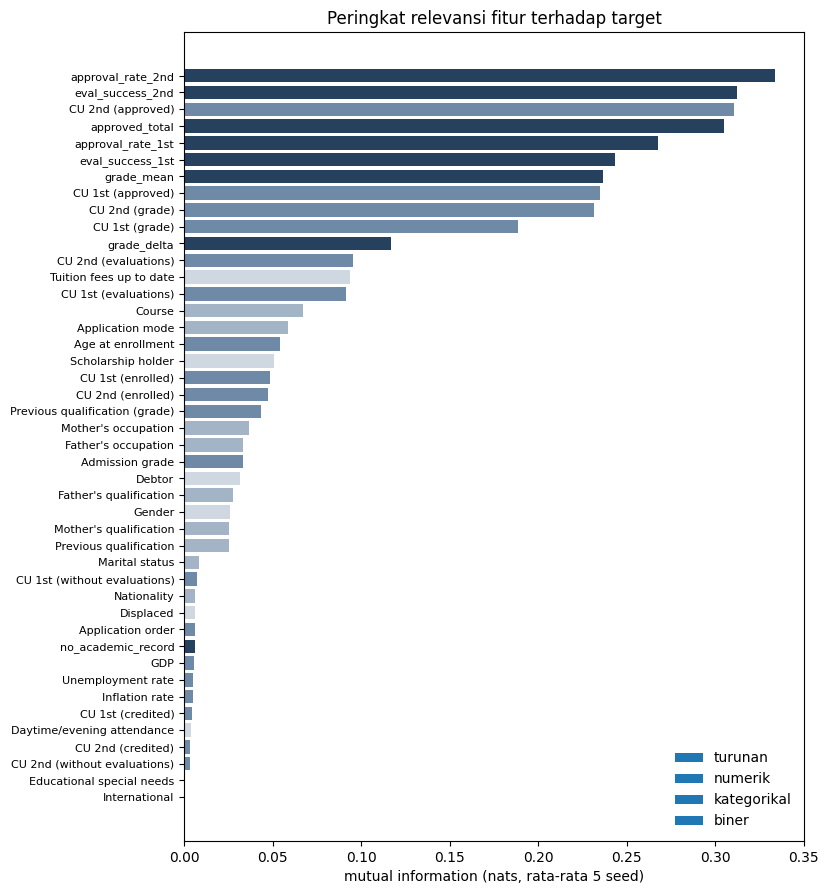

In [313]:
mi_cols = EDA_NUM + EDA_ENG + EDA_BIN + EDA_CAT
discrete = [c in EDA_BIN + EDA_CAT for c in mi_cols]
mi = pd.Series(np.mean([mutual_info_classif(eda_x[mi_cols], eda_x["Target"], discrete_features=discrete, random_state=s)
                        for s in range(5)], axis=0), index=mi_cols).sort_values(ascending=False)
kind = {**{c: "numerik" for c in EDA_NUM}, **{c: "turunan" for c in EDA_ENG}, **{c: "biner" for c in EDA_BIN}, **{c: "kategorikal" for c in EDA_CAT}}
palette = {"turunan": "#26415e", "numerik": "#6f8aa6", "kategorikal": "#a3b4c6", "biner": "#cfd8e1"}
fig, ax = plt.subplots(figsize=(8, 10.5))
ax.barh([short(c) for c in mi.index][::-1], mi.values[::-1], color=[palette[kind[c]] for c in mi.index][::-1])
for k, col in palette.items():
    ax.barh([], [], color=col, label=k)
ax.legend(frameon=False, loc="lower right")
ax.set_xlabel("mutual information (nats, rata-rata 5 seed)")
ax.set_title("Peringkat relevansi fitur terhadap target")
ax.tick_params(axis="y", labelsize=8)
plt.show()

**Catatan**

* Urutan fitur menurut MI mirip dengan hasil Kruskal-Wallis. Rasio kelulusan semester 2 ada di posisi paling atas, dan 4 dari 6 posisi teratas diisi fitur turunan.
* Fitur demografis dan makroekonomi ada di urutan bawah. Hasil ini sejalan dengan seleksi fitur Information Gain di bagian 1.7.

#### 1.3.11 Subkelompok: catatan akademik kosong, umur, finansial, angkatan

In [314]:
academic = [sem(s, f) for s in ("1st", "2nd") for f in EDA_SEM]
zero = (eda[sem("1st", "enrolled")] == 0) & (eda[sem("2nd", "enrolled")] == 0)
zero_t = (eda_test[sem("1st", "enrolled")] == 0) & (eda_test[sem("2nd", "enrolled")] == 0)
print("Tanpa satu pun mata kuliah di kedua semester (train / test):", int(zero.sum()), "/", int(zero_t.sum()))
print("Semua 12 kolom akademik nol pada kelompok ini:", bool((eda.loc[zero, academic] == 0).all().all()))
print("Program studi kelompok ini:", eda.loc[zero, "Course"].map(eda_labels["Course"]).value_counts().to_dict())
print("Jumlah mahasiswa prodi tersebut (train / test):", int((eda["Course"] == 171).sum()), "/", int((eda_test["Course"] == 171).sum()))
display(pd.crosstab(zero.map({True: "tanpa catatan akademik", False: "ada catatan akademik"}), eda["Target"], normalize="index")[EDA_CLASSES])

age_bin = pd.cut(eda["Age at enrollment"], [16, 19, 22, 25, 30, 40, 70], labels=["17-19", "20-22", "23-25", "26-30", "31-40", "41-70"])
display(pd.crosstab(age_bin, eda["Target"], normalize="index")[EDA_CLASSES].assign(n=age_bin.value_counts()))

fin = eda.assign(SPP=eda["Tuition fees up to date"].map({1: "SPP lancar", 0: "SPP menunggak"}),
                 Beasiswa=eda["Scholarship holder"].map({1: "beasiswa", 0: "tanpa beasiswa"}))
display(fin.groupby(["SPP", "Beasiswa"])["Target"].value_counts(normalize=True).unstack()[EDA_CLASSES]
        .assign(n=fin.groupby(["SPP", "Beasiswa"]).size()))

macro = ["Unemployment rate", "Inflation rate", "GDP"]
chi2, p, dof, v = cramers_v(eda[macro].astype(str).agg("|".join, axis=1), eda["Target"])
print(f"Angkatan (10 kombinasi makroekonomi) vs target: chi2 = {chi2:.1f}, p = {p:.3g}, Cramér's V = {v:.3f}")

Tanpa satu pun mata kuliah di kedua semester (train / test): 137 / 43
Semua 12 kolom akademik nol pada kelompok ini: True
Program studi kelompok ini: {'Animation and Multimedia Design': 137}
Jumlah mahasiswa prodi tersebut (train / test): 159 / 56


Target,Dropout,Enrolled,Graduate
row_0,,,
ada catatan akademik,0.316661,0.180804,0.502535
tanpa catatan akademik,0.416058,0.153285,0.430657


Target,Dropout,Enrolled,Graduate,n
Age at enrollment,,,,
17-19,0.209019,0.167502,0.623479,1397
20-22,0.257294,0.229443,0.513263,754
23-25,0.455752,0.230088,0.314159,226
26-30,0.589641,0.163347,0.247012,251
31-40,0.566879,0.130573,0.302548,314
41-70,0.512987,0.097403,0.389610,154


Target                         Dropout  Enrolled  Graduate     n
SPP           Beasiswa                                          
SPP lancar    beasiswa        0.100000  0.110667  0.789333   750
              tanpa beasiswa  0.302479  0.224583  0.472939  1977
SPP menunggak beasiswa        0.625000  0.250000  0.125000    32
              tanpa beasiswa  0.893175  0.062315  0.044510   337

Angkatan (10 kombinasi makroekonomi) vs target: chi2 = 42.5, p = 0.00095, Cramér's V = 0.063


**Catatan**

* Temuan paling penting soal kualitas data: ada 137 mahasiswa yang semua 12 kolom akademiknya bernilai nol, dan semuanya berasal dari prodi Animation and Multimedia Design. Itu 137 dari 159 mahasiswa prodi ini di train, dan 43 dari 56 di test. Padahal 43% dari mereka justru Graduate. Jadi angka nol di sini artinya nilainya tidak tercatat, bukan mahasiswanya gagal semua mata kuliah.
* Baris-baris ini tetap dipakai, karena kasus yang sama juga ada di data test Kaggle dan tetap harus diprediksi. Karena `Course` di-one-hot, model tetap bisa membedakan mahasiswa prodi ini dari mahasiswa yang memang tidak lulus.
* Persentase Dropout naik seiring umur: 21% di umur 17 sampai 19 tahun, dan 59% di umur 26 sampai 30 tahun.
* Faktor keuangan sangat menentukan. Mahasiswa yang menunggak SPP dan tidak punya beasiswa (n = 337) 89% Dropout. Mahasiswa yang SPP-nya lancar dan punya beasiswa (n = 750) hanya 10% Dropout.
* Angkatan (10 kombinasi nilai makroekonomi) memang berhubungan dengan target, tapi lemah (Cramér's V = 0,063). Jadi variabel makroekonomi bukan prediktor utama.

#### 1.3.12 Struktur multivariat: proyeksi PCA

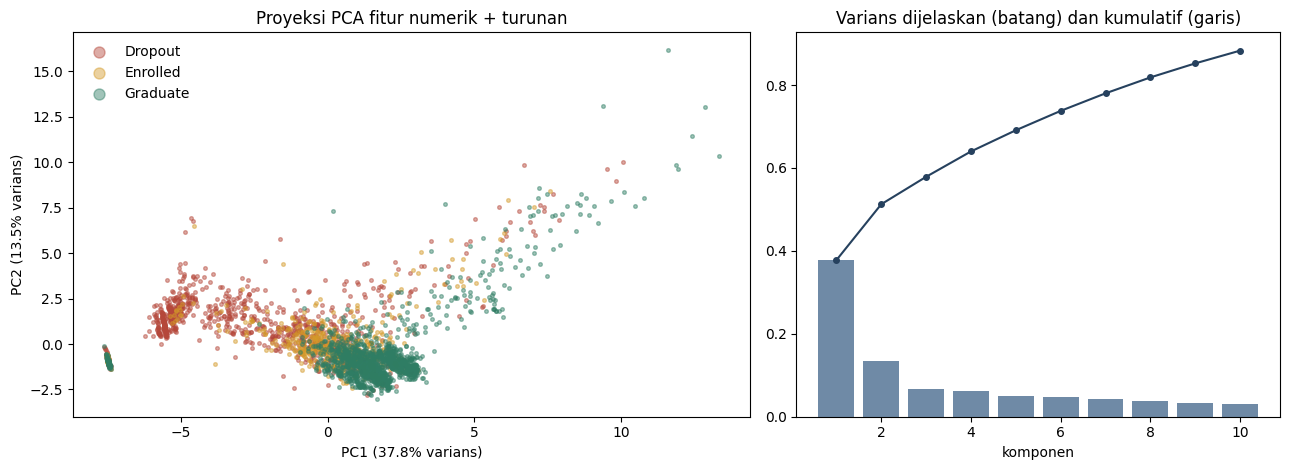

In [315]:
num_eng = EDA_NUM + EDA_ENG
Zp = (eda_x[num_eng] - eda_x[num_eng].mean()) / eda_x[num_eng].std(ddof=0)
pca = PCA(n_components=10, random_state=0).fit(Zp)
P = pca.transform(Zp)[:, :2]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.4, 1]})
for k in EDA_CLASSES:
    m = (eda_x["Target"] == k).to_numpy()
    axes[0].scatter(P[m, 0], P[m, 1], s=7, alpha=0.45, color=EDA_COLORS[k], label=k)
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} varians)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} varians)")
axes[0].set_title("Proyeksi PCA fitur numerik + turunan")
axes[0].legend(frameon=False, markerscale=3)
axes[1].bar(range(1, 11), pca.explained_variance_ratio_, color="#6f8aa6")
axes[1].plot(range(1, 11), np.cumsum(pca.explained_variance_ratio_), color="#26415e", marker="o", ms=4)
axes[1].set_title("Varians dijelaskan (batang) dan kumulatif (garis)")
axes[1].set_xlabel("komponen")
fig.tight_layout()
plt.show()

**Catatan**

* PC1 menjelaskan 37,8% variasi data, dan paling banyak dibentuk oleh jumlah mata kuliah yang lulus dan nilai. Jadi PC1 bisa dibaca sebagai sumbu prestasi akademik.
* Dropout banyak di sisi kiri, Graduate di sisi kanan, dan Enrolled ada di tengah, bercampur dengan dua kelas lainnya. Kelompok kecil yang terpisah di paling kiri adalah mahasiswa tanpa catatan akademik, isinya campuran ketiga kelas.
* Karena Dropout dan kelas lain terpisah hampir lurus di sepanjang PC1, Logistic Regression kemungkinan bisa bersaing dengan model yang lebih rumit. Untuk KNN, tetangga terdekat mahasiswa Enrolled sering berasal dari kelas lain, jadi recall Enrolled kemungkinan rendah.

#### 1.3.13 Pergeseran distribusi train vs test Kaggle

Kami cek dengan dua cara. Pertama, uji Kolmogorov-Smirnov untuk tiap fitur numerik, dengan koreksi Bonferroni. Kedua, adversarial validation: kami latih sebuah classifier untuk membedakan baris train dan baris test. Kalau ROC-AUC-nya sekitar 0,5, artinya classifier itu tidak bisa membedakan keduanya, dan skor validasi lokal bisa dipakai untuk memperkirakan skor Kaggle.

In [316]:
ks = pd.DataFrame([{"fitur": short(c), "KS": r.statistic, "p_value": r.pvalue} for c in EDA_NUM
                   for r in [stats.ks_2samp(eda[c], eda_test[c])]]).sort_values("KS", ascending=False)
print("Fitur dengan pergeseran signifikan (Bonferroni 5%):", int((ks["p_value"] < 0.05 / len(ks)).sum()), "dari", len(ks))
adv = pd.concat([eda[EDA_FEATURES].assign(is_test=0), eda_test[EDA_FEATURES].assign(is_test=1)], ignore_index=True)
auc = sk_cross_val_score_eda(SkRandomForestEDA(300, min_samples_leaf=5, n_jobs=-1, random_state=0), adv[EDA_FEATURES], adv["is_test"],
                             cv=SkStratifiedKFoldEDA(5, shuffle=True, random_state=0), scoring="roc_auc")
print(f"Adversarial validation ROC-AUC (5-fold): {auc.mean():.3f} ± {auc.std():.3f}")

Fitur dengan pergeseran signifikan (Bonferroni 5%): 0 dari 19
Adversarial validation ROC-AUC (5-fold): 0.480 ± 0.019


**Catatan**

* Tidak ada fitur numerik yang distribusinya berbeda nyata antara train dan test Kaggle (uji KS dengan koreksi Bonferroni).
* Adversarial validation menghasilkan ROC-AUC 0,480 ± 0,019, sama saja dengan menebak acak.
* Jadi train dan test berasal dari distribusi yang sama, dan skor validasi lokal bisa dipakai untuk memperkirakan skor Kaggle.

#### 1.3.14 Outlier

In [317]:
q1, q3 = eda[EDA_NUM].quantile(0.25), eda[EDA_NUM].quantile(0.75)
out_iqr = ((eda[EDA_NUM] < q1 - 1.5 * (q3 - q1)) | (eda[EDA_NUM] > q3 + 1.5 * (q3 - q1))).sum()
z = (eda[EDA_NUM] - eda[EDA_NUM].mean()) / eda[EDA_NUM].std()
outl = pd.DataFrame({"outlier_IQR": out_iqr, "outlier_|z|>3": (z.abs() > 3).sum()})
outl.index = [short(c) for c in outl.index]
display(outl.sort_values("outlier_IQR", ascending=False).head(10))
print("Komposisi kelas pada nilai semester 2 = 0:", eda.loc[eda[sem("2nd", "grade")] == 0, "Target"].value_counts(normalize=True).round(3).to_dict())

,outlier_IQR,outlier_|z|>3
CU 2nd (grade),630,0
CU 1st (grade),517,0
CU 1st (credited),409,103
CU 2nd (credited),373,76
Application order,370,86
Age at enrollment,307,70
CU 1st (enrolled),303,70
CU 2nd (enrolled),273,56
CU 1st (without evaluations),212,48
CU 2nd (without evaluations),194,61


Komposisi kelas pada nilai semester 2 = 0: {'Dropout': 0.835, 'Graduate': 0.095, 'Enrolled': 0.071}


**Catatan**

* Aturan 1,5 IQR menandai ratusan nilai sebagai outlier, tapi tidak ada satu pun yang nilainya mustahil. Outlier paling banyak adalah nilai semester 0, dan 83% di antaranya Dropout. Jadi outlier ini justru petunjuk yang kuat, bukan gangguan.
* Umur sampai 70 tahun dan nilai `credited` yang besar juga masuk akal (mahasiswa dewasa, atau mahasiswa pindahan yang banyak mata kuliahnya diakui).
* Karena itu outlier tidak dibuang dan tidak dipotong. Nilai kosong diisi median, dan standardisasi z-score tetap dipakai.

#### 1.3.15 Ringkasan EDA dan implikasinya untuk pemodelan

| # | Temuan EDA | Artinya untuk pemodelan |
|---|---|---|
| 1 | Ada nama kolom yang mengandung tab (`Daytime/evening attendance\t`) dan salah eja (`Nacionality`) | Rapikan nama kolom dulu, supaya pemanggilan kolom tidak gagal diam-diam |
| 2 | Tidak ada sel kosong, baris duplikat, atau nilai mustahil | Tidak ada baris yang perlu dibuang, tapi data baru tetap perlu dicek |
| 3 | 1 baris train dan 2 baris test melanggar `without evaluations <= enrolled` | Ini salah catat di satu sel; dampaknya kecil, dan sel itu bisa dikosongkan lalu diisi median |
| 4 | 15 baris test memakai kode kategori yang tidak ada di train | Encoder harus bisa menangani kategori baru (`handle_unknown` atau kategori `other`) |
| 5 | Kelas tidak seimbang 2,78 : 1; Enrolled hanya 18%; macro-F1 baseline 0,222 | Pakai macro-F1 dan metrik per kelas, jangan hanya akurasi; coba class weight atau SMOTE |
| 6 | Prestasi tahun pertama adalah prediktor terkuat, dan rasio lebih kuat dari jumlah mentah | Fitur kelulusan semester dipertahankan; rasio kelulusan layak dicoba sebagai fitur tambahan |
| 7 | Keuangan, prodi, jalur masuk, umur, dan gender berpengaruh sedang sampai kuat | Dipertahankan; prodi dan jalur masuk di-one-hot karena kodenya tidak berurutan |
| 8 | `Nationality`, `Educational special needs`, `International` tidak berpengaruh | Aman dibuang (Information Gain di bagian 1.7 juga membuangnya) |
| 9 | Fitur semester 1 dan 2 sangat mirip (VIF sampai 23,6) | Pakai regularisasi L2 di Logistic Regression; koefisiennya jangan dibaca sebagai sebab-akibat |
| 10 | 137 mahasiswa Animation and Multimedia Design tanpa catatan akademik (nilainya tidak tercatat) | Baris tetap dipakai; one-hot `Course` membantu model mengenali nilai nol yang bukan nol sungguhan |
| 11 | Skala fitur sangat berbeda; outlier masuk akal dan berguna | Standardisasi untuk KNN, Logistic Regression, dan ANN; outlier tidak dibuang |
| 12 | Enrolled bercampur dengan Dropout dan Graduate | Enrolled kemungkinan jadi kelas paling sulit untuk semua model |
| 13 | Distribusi train dan test sama (adversarial AUC 0,48) | Skor validasi lokal bisa dipakai untuk memperkirakan skor Kaggle |

###1.4 Cleaning missing value dan duplicate

In [319]:
print(f"Jumlah data missing: {train.isna().sum().sum()}")
train.isnull().sum()

Jumlah data missing: 0


,0
Student_ID,0
Marital status,0
Application mode,0
Application order,0
Course,0
Daytime/evening attendance\t,0
Previous qualification,0
Previous qualification (grade),0
Nacionality,0
Mother's qualification,0


In [320]:
n_dup = train.duplicated().sum()
print("Jumlah baris duplikat      :", n_dup)

train = train.drop_duplicates().reset_index(drop=True)
print("Jumlah baris setelah dihapus:", len(train))

Jumlah baris duplikat      : 0
Jumlah baris setelah dihapus: 3096


###1.5 Encode Kolom Kategorik (Target)

In [321]:
#Encode kolom Target: Dropout=0, Enrolled=1, Graduate=2

train["Target"] = train["Target"].map({"Dropout": 0, "Enrolled": 1,"Graduate":2})

####1.7 Standardisasi Data

###1.6 Split data Train/validasi = 80/20

In [322]:
x_all = train.drop(columns="Target")
y_all = train["Target"]

rng = np.random.default_rng(42)
val_idx = []
for c in np.unique(y_all):
    idx_c = rng.permutation(np.where(y_all == c)[0])
    val_idx.extend(idx_c[:round(0.2 * len(idx_c))])     # 20% tiap kelas -> validasi
is_val = np.isin(np.arange(len(y_all)), val_idx)

x_train, y_train = x_all[~is_val].reset_index(drop=True), y_all[~is_val]
x_val, y_val = x_all[is_val].reset_index(drop=True), y_all[is_val]

print("Train:", x_train.shape, "| Test:", x_val.shape)
print("Proporsi dropout train:", round(y_train.mean(), 4), "| test:", round(y_val.mean(), 4))

Train: (2477, 37) | Test: (619, 37)
Proporsi dropout train: 1.1784 | test: 1.1777


###1.7 Select feature

####1.7.1 Korelasi

In [323]:
corr = train.corr()["Target"].drop("Target")
corr_sorted = corr.reindex(corr.abs().sort_values(ascending=False).index)

pd.DataFrame({"korelasi": corr_sorted.round(4), "nilai_mutlak": corr_sorted.abs().round(4)})



,korelasi,nilai_mutlak
Curricular units 2nd sem (approved),0.6162,0.6162
Curricular units 2nd sem (grade),0.5667,0.5667
Curricular units 1st sem (approved),0.5164,0.5164
Curricular units 1st sem (grade),0.4849,0.4849
Tuition fees up to date,0.4129,0.4129
Scholarship holder,0.3027,0.3027
Debtor,-0.2519,0.2519
Age at enrollment,-0.2485,0.2485
Application mode,-0.2359,0.2359
Gender,-0.2263,0.2263


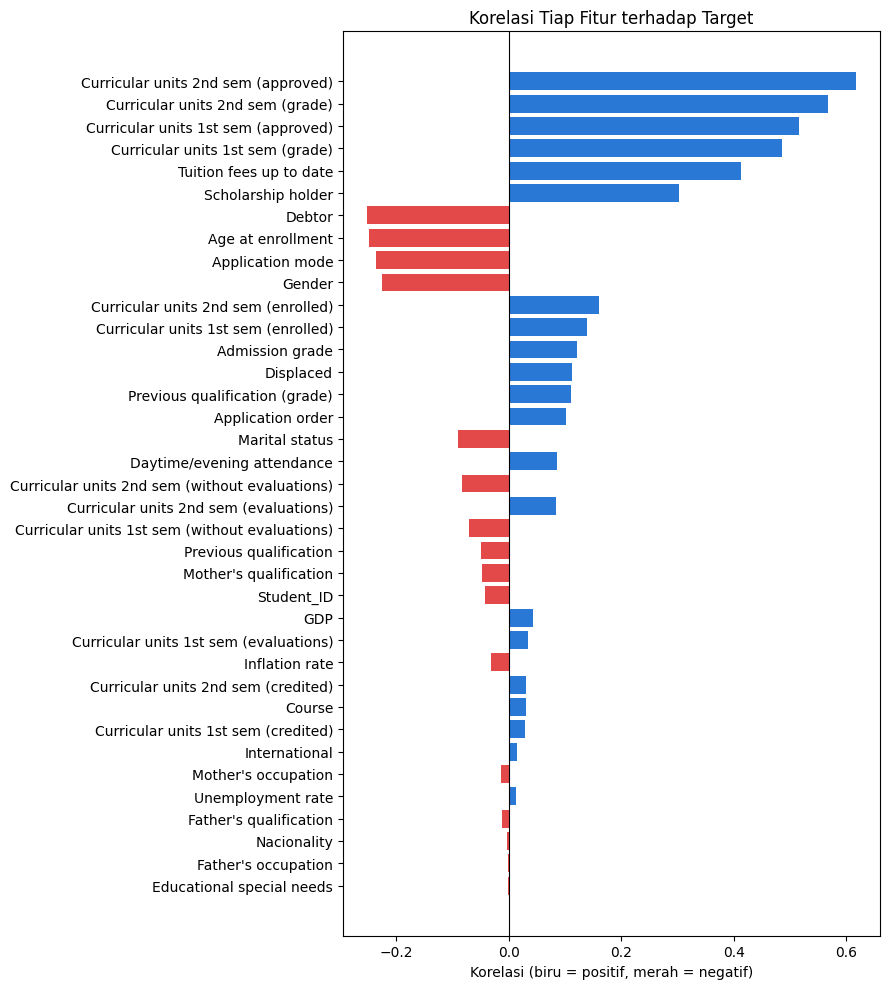

In [324]:
## Visualisasi Korelasi terhadap Target
plot_corr = corr_sorted.iloc[::-1]          # korelasi terkuat di atas
warna = ["#2a78d6" if c > 0 else "#e34948" for c in plot_corr]

plt.figure(figsize=(9, 10))
plt.barh(plot_corr.index.str.strip(), plot_corr.values, color=warna)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Korelasi Tiap Fitur terhadap Target")
plt.xlabel("Korelasi (biru = positif, merah = negatif)")
plt.tight_layout()
plt.show()

####1.6.2 Information Gain
gain = entropy(Target) - entropy(Target setelah dibagi per nilai fitur)

In [325]:
def entropy(y):
    p = np.bincount(y) / len(y)
    p = p[p > 0]
    return -(p * np.log2(p)).sum()

def information_gain(x, y):
    entropy_awal = entropy(y)

    entropy_baru = 0

    for nilai in np.unique(x):
        subset = y[x == nilai]
        entropy_baru += (len(subset) / len(y)) * entropy(subset)

    return entropy_awal - entropy_baru

def to_discrete(values):
    if pd.api.types.is_numeric_dtype(values) and values.nunique() > 20:
        return pd.qcut(values, q=10, labels=False, duplicates="drop").to_numpy()
    return values.astype(str).to_numpy()

shuffle_rng = np.random.default_rng(0)
rows = []
for col in x_train.columns:
    x = to_discrete(x_train[col])
    gain = information_gain(x, y_train)
    rows.append({"fitur": col, "gain": gain})
gain_table = pd.DataFrame(rows).sort_values("gain", ascending=False).reset_index(drop=True)

# buang: fitur dengan gain < 0.02
drop_cols = gain_table.loc[gain_table["gain"] < 0.02,"fitur"].tolist()
print("Fitur dibuang:", drop_cols)
gain_table.round(4)

Fitur dibuang: ['Application order', 'Marital status', 'Nacionality', 'Curricular units 1st sem (without evaluations)', "Father's qualification", 'GDP', 'Unemployment rate', 'Curricular units 2nd sem (credited)', "Father's occupation", "Mother's qualification", 'Curricular units 2nd sem (without evaluations)', "Mother's occupation", 'Inflation rate', 'Student_ID', 'Displaced', 'Daytime/evening attendance\t', 'Curricular units 1st sem (credited)', 'International', 'Educational special needs']


,fitur,gain
0,Curricular units 2nd sem (approved),0.4488
1,Curricular units 1st sem (approved),0.3183
2,Curricular units 2nd sem (grade),0.3020
3,Curricular units 1st sem (grade),0.2172
4,Curricular units 2nd sem (evaluations),0.1396
5,Tuition fees up to date,0.1284
6,Curricular units 1st sem (evaluations),0.1128
7,Course,0.0928
8,Application mode,0.0852
9,Age at enrollment,0.0847


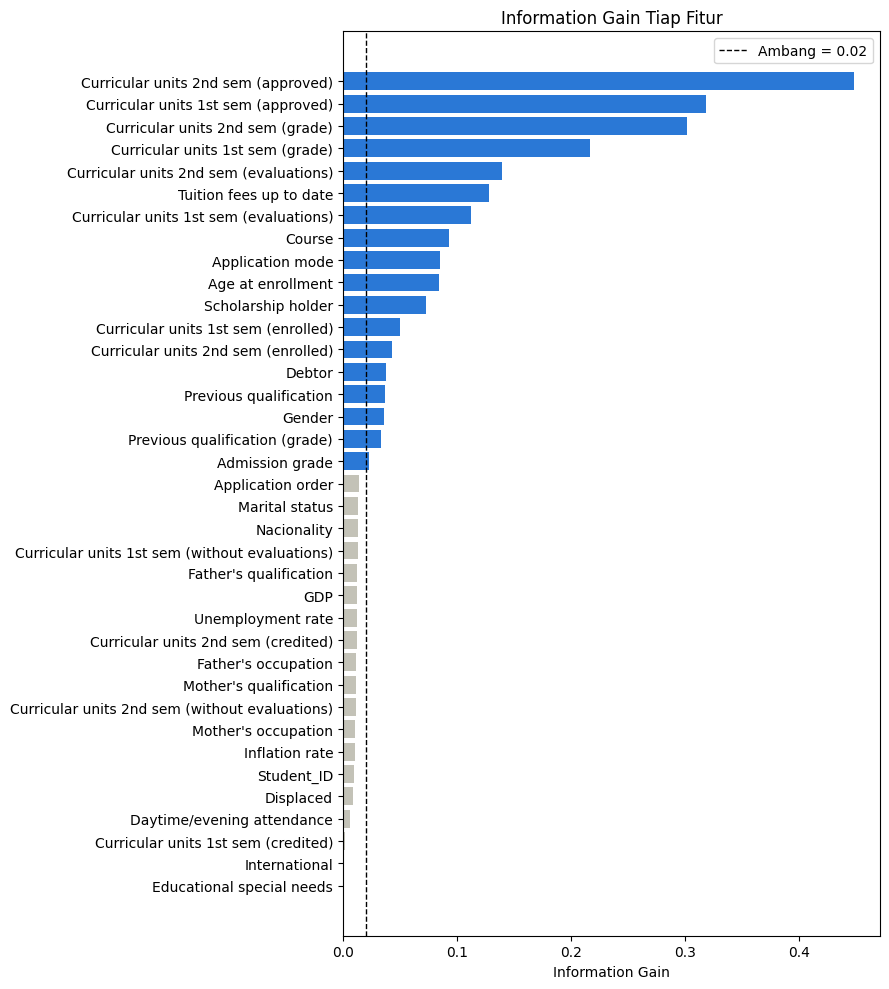

In [326]:
#Plot Information Gain
plot_df = gain_table.sort_values("gain")
warna = ["#2a78d6" if g >= 0.02 else "#c3c2b7" for g in plot_df["gain"]]

plt.figure(figsize=(9, 10))
plt.barh(plot_df["fitur"].str.strip(), plot_df["gain"], color=warna)
plt.axvline(0.02, color="black", linestyle="--", linewidth=1, label="Ambang = 0.02")
plt.title("Information Gain Tiap Fitur")
plt.xlabel("Information Gain")
plt.legend()
plt.tight_layout()
plt.show()

####1.6.3 Fitur Terpilih


Pertimbangan Pemilihan Fitur menggunakan Information Gain karena
Information Gain merupakan kriteria pemisahan yang dipakai Decision Tree (ID3) yang kami implementasikan,   sehingga seleksi fitur dan model memakai ukuran yang sama. Selain itu batas gain 0.02 kami pilih karena ada jarak yang cukup dalam antara Gain "Admission Grade" dengan Gain fitur dibawahnya dari 0,0225 ke 0,014

In [327]:
x_train, y_train, x_val, y_val  = [df.drop(columns=drop_cols) for df in [x_train, y_train, x_val, y_val]]
y_train = y_train.reset_index(drop=True)
y_val   = y_val.reset_index(drop=True)

print(f"Selected Features:\n{gain_table[gain_table["gain"]>0.02]}")

Selected Features:
                                     fitur      gain
0      Curricular units 2nd sem (approved)  0.448820
1      Curricular units 1st sem (approved)  0.318264
2         Curricular units 2nd sem (grade)  0.301955
3         Curricular units 1st sem (grade)  0.217220
4   Curricular units 2nd sem (evaluations)  0.139636
5                  Tuition fees up to date  0.128438
6   Curricular units 1st sem (evaluations)  0.112784
7                                   Course  0.092772
8                         Application mode  0.085163
9                        Age at enrollment  0.084730
10                      Scholarship holder  0.073230
11     Curricular units 1st sem (enrolled)  0.049910
12     Curricular units 2nd sem (enrolled)  0.042806
13                                  Debtor  0.037674
14                  Previous qualification  0.036789
15                                  Gender  0.036027
16          Previous qualification (grade)  0.033663
17                         

In [328]:
x_train.head()


,Application mode,Course,Previous qualification,Previous qualification (grade),Admission grade,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade)
0,17,9670,1,118.0,113.5,0,1,0,1,19,6,9,5,13.500000,6,6,6,14.000000
1,1,9500,1,138.0,144.3,0,1,0,0,20,7,9,6,12.700000,8,8,7,13.571429
2,17,9773,1,138.0,124.0,0,1,0,1,19,6,6,6,13.166667,6,6,6,13.833333
3,7,9500,2,140.0,140.0,0,1,0,0,29,8,14,4,11.325000,8,14,4,11.325000
4,17,9070,1,119.0,115.2,0,1,1,1,21,6,8,4,11.500000,6,7,5,11.000000


In [329]:
y_train

,Target
0,2
1,2
2,2
3,0
4,0
...,...
2472,0
2473,2
2474,2
2475,2


In [330]:
x_val.head()

,Application mode,Course,Previous qualification,Previous qualification (grade),Admission grade,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade)
0,1,9070,1,139.0,134.9,0,1,1,0,20,6,7,6,13.666667,6,7,6,12.166667
1,43,8014,14,133.1,100.0,0,0,0,0,34,7,13,3,12.000000,7,15,1,13.000000
2,17,9070,1,134.0,133.3,0,1,1,0,18,6,7,5,10.800000,6,6,0,0.000000
3,43,9130,1,156.0,156.0,1,0,1,0,24,6,11,5,11.833333,6,11,4,11.500000
4,1,9670,1,117.0,113.5,0,1,0,0,20,5,6,4,11.500000,5,5,4,10.750000


In [331]:
y_val

,Target
0,2
1,0
2,0
3,0
4,2
...,...
614,0
615,2
616,2
617,2


### 1.8 Fungsi untuk Evaluasi Model

In [332]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

KELAS = ["Dropout", "Enrolled", "Graduate"]

def model_eval(y_true, y_pred, nama_model="Model"):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)

    metrik = pd.Series({
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall":    recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1-score":  f1_score(y_true, y_pred, average="macro", zero_division=0),
    }, name=nama_model).round(4)
    display(metrik.to_frame("Nilai (macro)"))

    print(classification_report(y_true, y_pred, labels=[0, 1, 2],
                                target_names=KELAS, zero_division=0))

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=[f"Pred {k}" for k in KELAS],
                yticklabels=[f"Aktual {k}" for k in KELAS])
    plt.title(f"Confusion Matrix - {nama_model} (Data Validasi)")
    plt.xlabel("Prediksi")
    plt.ylabel("Aktual")
    plt.tight_layout()
    plt.show()

    return metrik

##2. Implementasi Model

In [333]:
import os

FOLDER_MODEL = "saved_models"
os.makedirs(FOLDER_MODEL, exist_ok=True)

LATIH_ULANG = False   # ubah ke True kalau ingin memaksa training ulang

###2.1 Implementasi Decision Tree Learning (DTL)

In [334]:
from tqdm import tqdm
import pickle

class DecisionTreeClassifier():
    def __init__(self, max_depth = None, min_samples_split = None, min_samples_leaf = None, max_features = None):
        self.__features = None
        self.__target = None
        self.__tree = None
        self.__weights = None
        self.__max_depth = max_depth
        self.__min_samples_split = min_samples_split
        self.__min_samples_leaf = min_samples_leaf
        self.__max_features = max_features
        self.__thresholds = {}

    def fit(self, features, target, discretize = None, discretization_max_depth = None):
        self.__features = features.reset_index(drop = True)
        self.__target = target.reset_index(drop = True)
        self.__weights = pd.Series(np.ones(len(self.__features)))

        if discretize is not None:
            self.__features = self.__discretize(self.__features, self.__target, self.__weights, discretize, discretization_max_depth)

        if self.__max_depth is not None:
            self.__tree = self.__id3(self.__features, self.__target, self.__weights, 1)
        else:
            self.__tree = self.__id3(self.__features, self.__target, self.__weights)

        return self.__tree

    def predict(self, features, voting = 'hard'):
        features = self.__transform(features)
        predictions = [self.__tree_traversal(self.__tree, features.iloc[i]) for i in range(len(features))]

        if voting != 'hard':
            return predictions
        else:
            return [max(prediction, key=prediction.get) for prediction in predictions]

    def save_to_pickle(self, model_name = None, save_to = None):
        if model_name is None:
            raise ValueError("Please provide model name through model_name argument. Example: model.pkl")

        model_data = {
            "features": self.__features,
            "target": self.__target,
            "tree": self.__tree,
            "weights": self.__weights,
            "max_depth": self.__max_depth,
            "min_samples_split": self.__min_samples_split,
            "min_samples_leaf": self.__min_samples_leaf,
            "max_features": self.__max_features,
            "thresholds": self.__thresholds
        }

        if save_to is None:
            with open(model_name, 'wb') as f:
                pickle.dump(model_data, f)
        else:
            if save_to[-1] == '/':
                with open(save_to + '/' + model_name, 'w') as f:
                    pickle.dump(model_data, f)
            else:
                with open(save_to + model_name, 'w') as f:
                    pickle.dump(model_data, f)

    def load_from_pickle(self, pickle_dir):
        with open(pickle_dir, 'rb') as f:
            model_data = pickle.load(f)

        self.__features = model_data["features"]
        self.__target = model_data["target"]
        self.__tree = model_data["tree"]
        self.__weights = model_data["weights"]
        self.__max_depth = model_data["max_depth"]
        self.__min_samples_split = model_data["min_samples_split"]
        self.__min_samples_leaf = model_data["min_samples_leaf"]
        self.__max_features = model_data["max_features"]
        self.__thresholds = model_data["thresholds"]

    def __entropy(self, features, weights):
        unique_elements = np.unique(features)
        counts = np.array([np.sum(weights[features == value]) for value in unique_elements])

        entropy_value = -np.sum([
            (counts[i] / np.sum(counts)) * np.log2(counts[i] / np.sum(counts))
            for i in range(len(unique_elements)) if counts[i] > 0])

        return entropy_value

    def __information_gain(self, feature, target, weights):
        assert len(feature) == len(target), 'length of feature and target is not matched'

        not_missing_feature = feature[feature.notna()]
        not_missing_target = target[feature.notna()]
        not_missing_weights = weights[feature.notna()]

        if np.sum(not_missing_weights) == 0:
            return 0

        total_entropy = self.__entropy(not_missing_target, not_missing_weights)
        values= np.unique(not_missing_feature)
        counts = np.array([np.sum(not_missing_weights[not_missing_feature == value]) for value in values])

        weighted_entropy = np.sum([
            (counts[i] / np.sum(counts)) * self.__entropy(not_missing_target[not_missing_feature == values[i]],
                                                          not_missing_weights[not_missing_feature == values[i]])
            for i in range(len(values))])

        not_missing_fraction = np.sum(not_missing_weights) / np.sum(weights)

        return not_missing_fraction * (total_entropy - weighted_entropy)

    def __id3(self, features, target, weights, tree_depth = None, parent_node_class=None):
        assert len(features) == len(target), 'length of feature and target is not matched'

        if self.__min_samples_leaf is not None:
            if len(features) < self.__min_samples_leaf:
                return parent_node_class

        if (len(features) == 0):
            return parent_node_class

        if len(np.unique(target)) == 1:
            return np.unique(target)[0]

        unique_elements = np.unique(target)
        counts = np.array([np.sum(weights[target == value]) for value in unique_elements])

        parent_node_class = unique_elements[np.argmax(counts)]

        if tree_depth is not None:
            if tree_depth >= self.__max_depth:
                return parent_node_class

        if self.__min_samples_split is not None:
            if len(features) < self.__min_samples_split:
                return parent_node_class

        if features.shape[1] == 0:
            return parent_node_class


        if self.__max_features is not None:
            columns = np.random.choice(features.columns, size = min(self.__max_features, len(features.columns)), replace=False)
        else:
            columns = features.columns

        gains = [self.__information_gain(features[column], target, weights) for column in columns]
        if np.max(gains) < 1e-12:
            return parent_node_class

        best_feature = columns[np.argmax(gains)]

        tree = {best_feature: {}}
        not_best_feature = [f for f in features.columns if f != best_feature]
        not_missing_feature = features[best_feature].notna()
        missing_feature = features[best_feature].isna()

        values = np.unique(features.loc[not_missing_feature, best_feature])
        counts = np.array([np.sum(weights[not_missing_feature & (features[best_feature] == value)]) for value in values])
        probabilities = counts / np.sum(counts)
        tree["__probabilities__"] = {
            (value.item() if isinstance(value, np.generic) else value): float(probability)
            for value, probability in zip(values, probabilities)
        }

        for i, value in enumerate(values):
            selected = (features[best_feature] == value) | missing_feature

            subset = features[selected][not_best_feature].reset_index(drop = True)
            subset_target =  target.loc[selected].reset_index(drop = True)
            subset_weights = weights.loc[selected].reset_index(drop = True)
            subset_weights.loc[missing_feature[selected].to_numpy()] *= probabilities[i]

            if tree_depth is not None:
                subtree = self.__id3(subset, subset_target, subset_weights, tree_depth + 1, parent_node_class)
            else:
                subtree = self.__id3(subset, subset_target, subset_weights, tree_depth, parent_node_class)

            key = value.item() if isinstance(value, np.generic) else value
            tree[best_feature][key] = subtree

        return tree

    def __tree_traversal(self, tree, features):
        if not isinstance(tree, dict):
            return {tree: 1.0}

        feature = next(key for key in tree if key != "__probabilities__")
        value = features[feature]

        if pd.notna(value) and value in tree[feature]:
            subtree = tree[feature][value]
            return self.__tree_traversal(subtree, features)

        predictions = {}

        for branch, subtree in tree[feature].items():
            result = self.__tree_traversal(subtree, features)
            probability = tree["__probabilities__"][branch]

            for label, score in result.items():
                predictions[label] = (
                    predictions.get(label, 0.0)
                    + probability * score
                )

        return predictions

    def __find_thresholds(self, feature, target, weights, discretization_max_depth, depth = 0):
        if discretization_max_depth is not None and depth >= discretization_max_depth:
            return []

        not_missing_feature = feature[feature.notna()]
        not_missing_target = target[feature.notna()]
        not_missing_weights = weights[feature.notna()]

        values = np.sort(not_missing_feature.unique())

        if len(values) < 2 or not_missing_target.nunique() <= 1:
            return []

        candidates = (values[:-1] + values[1:]) / 2

        gains = []

        for threshold in candidates:
            categorical = pd.Series(np.where(not_missing_feature <= threshold, 0, 1), index=not_missing_feature.index)
            gains.append(self.__information_gain(categorical, not_missing_target, not_missing_weights))

        best_idx = np.argmax(gains)
        best_gain = gains[best_idx]

        if best_gain <= 1e-12:
            return []

        threshold = candidates[best_idx]

        left = not_missing_feature <= threshold
        right = ~left

        return (
            self.__find_thresholds(not_missing_feature.loc[left], not_missing_target.loc[left],
                                   not_missing_weights.loc[left], discretization_max_depth, depth + 1) + [threshold]
            + self.__find_thresholds(not_missing_feature.loc[right], not_missing_target.loc[right],
                                     not_missing_weights.loc[right], discretization_max_depth, depth + 1)
        )

    def __discretize(self, features, target, weights, columns, discretization_max_depth):
        features = features.copy()
        self.__thresholds = {}

        for column in columns:
            thresholds = sorted(
                self.__find_thresholds(features[column], target, weights, discretization_max_depth)
            )

            self.__thresholds[column] = thresholds

            bounds = np.array(thresholds + [np.inf])

            indices = np.searchsorted(
                thresholds,
                features.loc[features[column].notna(), column].to_numpy(),
                side="left"
            )

            features[column] = features[column].astype(float)
            features.loc[features[column].notna(), column] = bounds[indices]

        return features

    def __transform(self, features):
        features = features.copy()

        for column, thresholds in self.__thresholds.items():
            bounds = np.array(thresholds + [np.inf])

            indices = np.searchsorted(
                thresholds,
                features.loc[features[column].notna(), column].to_numpy(),
                side="left"
            )

            features[column] = features[column].astype(float)
            features.loc[features[column].notna(), column] = bounds[indices]

        return features

In [335]:
import os

cont_cols = [
    "Previous qualification (grade)", "Admission grade", "Age at enrollment",
    "Curricular units 1st sem (grade)", "Curricular units 2nd sem (grade)",
    "Curricular units 1st sem (enrolled)", "Curricular units 1st sem (evaluations)",
    "Curricular units 1st sem (approved)", "Curricular units 2nd sem (enrolled)",
    "Curricular units 2nd sem (evaluations)", "Curricular units 2nd sem (approved)",
]

os.makedirs("saved_models", exist_ok=True)
path_dtl = "saved_models/dtl.pkl"

dtl = DecisionTreeClassifier(max_depth=6, min_samples_leaf=5)

if os.path.exists(path_dtl) and LATIH_ULANG==False:
    dtl.load_from_pickle(path_dtl)
    print("DTL dimuat dari", path_dtl)
else:
    dtl.fit(x_train, y_train, discretize=cont_cols, discretization_max_depth=3)
    dtl.save_to_pickle(path_dtl)
    print("DTL dilatih dan disimpan ke", path_dtl)

pred_dtl = np.array(dtl.predict(x_val))
print("Akurasi validasi DTL:", round(np.mean(pred_dtl == y_val.to_numpy()), 4))

DTL dimuat dari saved_models/dtl.pkl
Akurasi validasi DTL: 0.7189


###2.2 Implementasi Random Forest


In [336]:
class RandomForestClassifier():
    def __init__(self, num_of_trees = None, tree_max_depth = None, tree_min_samples_split = None, tree_min_samples_leaf = None, tree_max_features = None, bootstrap_samples = None):
        self.__features = None
        self.__target = None
        self.__num_of_trees = num_of_trees
        self.__tree_max_depth = tree_max_depth
        self.__tree_min_samples_split = tree_min_samples_split
        self.__tree_min_samples_leaf = tree_min_samples_leaf
        self.__tree_max_features = tree_max_features
        self.__num_bootstrap_samples = bootstrap_samples
        self.__trees = []

    def fit(self, features, target, discretize, discretization_max_depth):
        self.__features = features
        self.__target = target

        if self.__num_of_trees is None:
            for _ in tqdm(range(100), desc = "creating trees"):
                self.__trees.append(self.__create_trees(discretize, discretization_max_depth))
        else:
            for _ in tqdm(range(self.__num_of_trees), desc = "creating trees"):
                self.__trees.append(self.__create_trees(discretize, discretization_max_depth))

    def predict(self, features, voting = 'hard'):
        if voting != 'hard':
            predictions = np.array([tree.predict(features, voting = 'soft') for tree in self.__trees])
            return [max(self.__target.unique(), key=lambda label: np.mean([p.get(label, 0) for p in predictions[:, i]])) for i in range(len(features))]
        else:
            predictions = np.array([tree.predict(features) for tree in self.__trees])
            return [pd.Series(predictions[:, i]).mode().iloc[0] for i in range(len(features))]

    def save_to_pickle(self, model_name = None, save_to = None):
        if model_name is None:
            raise ValueError("Please provide model name through model_name argument. Example: model.pkl")

        model_data = {
            "features": self.__features,
            "target": self.__target,
            "num_of_tree": self.__num_of_trees,
            "tree_max_depth": self.__tree_max_depth,
            "tree_min_samples_split": self.__tree_min_samples_split,
            "tree_min_samples_leaf": self.__tree_min_samples_leaf,
            "tree_max_features": self.__tree_max_features,
            "bootstrap_samples": self.__num_bootstrap_samples,
            "trees": self.__trees
        }

        if save_to is None:
            with open(model_name, 'wb') as f:
                pickle.dump(model_data, f)
        else:
            if save_to[-1] == '/':
                with open(save_to + '/' + model_name, 'w') as f:
                    pickle.dump(model_data, f)
            else:
                with open(save_to + model_name, 'w') as f:
                    pickle.dump(model_data, f)

    def load_from_pickle(self, pickle_dir):
        with open(pickle_dir, 'rb') as f:
            model_data = pickle.load(f)

        self.__features = model_data["features"]
        self.__target = model_data["target"]
        self.__num_of_trees = model_data["num_of_tree"]
        self.__tree_max_depth = model_data["tree_max_depth"]
        self.__tree_min_samples_split = model_data["tree_min_samples_split"]
        self.__tree_min_samples_leaf = model_data["tree_min_samples_leaf"]
        self.__tree_max_features = model_data["tree_max_features"]
        self.__num_bootstrap_samples = model_data["bootstrap_samples"]
        self.__trees = model_data["trees"]

    def __create_trees(self, discretize, discretization_max_depth):
        tree = DecisionTreeClassifier(max_depth = self.__tree_max_depth, min_samples_leaf = self.__tree_min_samples_leaf,
                                      min_samples_split = self.__tree_min_samples_split, max_features = self.__tree_max_features)
        tree_samples, tree_target = self.__bootstrap_samples()
        tree.fit(tree_samples, tree_target, discretize, discretization_max_depth)

        return tree

    def __bootstrap_samples(self):
        indexes = list(self.__features.index)

        if self.__num_bootstrap_samples is None:
            sample_indexes = np.random.choice(indexes, size = len(self.__features), replace=True)
        else:
            sample_indexes = np.random.choice(indexes, size = self.__num_bootstrap_samples, replace=True)

        sampled_features = self.__features.loc[sample_indexes].reset_index(drop = True)
        sampled_target = self.__target.loc[sample_indexes].reset_index(drop = True)

        return sampled_features, sampled_target


In [337]:
import os

path_rf = "saved_models/rf.pkl"
rf = RandomForestClassifier(num_of_trees=20, tree_max_depth=6,
                            tree_min_samples_leaf=5, tree_max_features=4)

if os.path.exists(path_rf):
    rf.load_from_pickle(path_rf)
    print("RF dimuat dari", path_rf)
else:
    np.random.seed(42)
    rf.fit(x_train, y_train, cont_cols, 3)
    rf.save_to_pickle(path_rf)
    print("RF dilatih dan disimpan ke", path_rf)

pred_rf = np.array(rf.predict(x_val))
print("Akurasi validasi RF:", round(np.mean(pred_rf == y_val.to_numpy()), 4))

RF dimuat dari saved_models/rf.pkl
Akurasi validasi RF: 0.7658


###2.3 Implementasi K-Nearest Neighbors (KNN)

Kedua model memakai split dan fitur yang sama dengan anggota lain, yaitu `x_train`, `y_train`, `x_val`, `y_val` dari bagian 1. Isinya 18 fitur hasil seleksi Information Gain, dengan label 0/1/2. KNN dan Logistic Regression butuh dua langkah preprocessing tambahan. Keduanya hanya di-fit pada data latih:

* One-hot encoding untuk kolom kode (`Application mode`, `Course`, `Previous qualification`). Kode-kode ini tidak punya urutan. Kalau dipakai langsung sebagai angka, KNN akan menghitung jarak yang tidak bermakna dan Logistic Regression akan memberi koefisien yang menyesatkan. Kode yang tidak pernah muncul saat training diubah menjadi vektor nol.
* Standardisasi z-score untuk kolom lainnya. Tanpa ini, fitur yang angkanya besar (misalnya nilai masuk 95 sampai 190) akan menguasai perhitungan jarak KNN, dan gradient descent Logistic Regression jadi lambat konvergen.

Urutan dan isi kolomnya kami buat sama dengan `buat_preprocessor()` di bagian 3.1, supaya versi scratch dan versi scikit-learn menerima matriks yang persis sama.

Hyperparameter dipilih dengan 5-fold stratified cross-validation di `x_train`, dan preprocessing di-fit ulang di setiap fold. Dengan begitu `x_val` sama sekali tidak dipakai untuk memilih model, jadi tetap bisa dipakai sebagai penilaian akhir yang adil.

In [338]:
import pickle
import time
from pathlib import Path
from sklearn.metrics import f1_score as sk_f1, accuracy_score as sk_acc
from sklearn.model_selection import StratifiedKFold as SkStratifiedKFold

SEED = 42
KOLOM_NOMINAL_SCRATCH = ["Application mode", "Course", "Previous qualification"]
FORMAT_VERSION = 1


FORMAT_VERSION = 1


class BaseClassifier:
    """Common API: fit, predict_proba, predict, score, get_params, save, load."""

    def _encode_labels(self, y):
        y = np.asarray(y)
        if y.ndim != 1:
            raise ValueError(f"y must be 1-D, got shape {y.shape}")
        self.classes_, y_enc = np.unique(y, return_inverse=True)
        if len(self.classes_) < 2:
            raise ValueError("need at least two classes to train a classifier")
        return y_enc.astype(np.int64)

    def predict_proba(self, X):
        raise NotImplementedError

    def predict(self, X):
        proba = self.predict_proba(X)
        return self.classes_[np.argmax(proba, axis=1)]

    def score(self, X, y):
        """Accuracy on (X, y)."""
        return float(np.mean(self.predict(X) == np.asarray(y)))

    def get_params(self):
        return {k: v for k, v in self.__dict__.items() if not k.endswith("_") and not k.startswith("_")}

    def save(self, path):
        """Pickle the model state together with its class name and a format version."""
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        payload = {"format_version": FORMAT_VERSION, "class_name": type(self).__name__, "state": self.__dict__}
        with open(path, "wb") as fh:
            pickle.dump(payload, fh, protocol=pickle.HIGHEST_PROTOCOL)
        return path

    @classmethod
    def load(cls, path):
        with open(path, "rb") as fh:
            payload = pickle.load(fh)
        if payload.get("class_name") != cls.__name__:
            raise TypeError(f"{path} holds a {payload.get('class_name')}, not a {cls.__name__}")
        if payload.get("format_version") != FORMAT_VERSION:
            raise ValueError(f"{path} uses format version {payload.get('format_version')}, expected {FORMAT_VERSION}")
        obj = cls.__new__(cls)
        obj.__dict__.update(payload["state"])
        return obj

    def __repr__(self):
        params = ", ".join(f"{k}={v!r}" for k, v in self.get_params().items())
        return f"{type(self).__name__}({params})"


def check_array(X):
    """Convert DataFrame or array-like input to a finite 2-D float array."""
    if hasattr(X, "to_numpy"):
        X = X.to_numpy()
    X = np.asarray(X, dtype=np.float64)
    if X.ndim != 2:
        raise ValueError(f"expected a 2-D array, got shape {X.shape}")
    if not np.isfinite(X).all():
        raise ValueError("input contains NaN or infinity; impute missing values before KNN or logistic regression")
    return X


class ScratchPreprocessor:
    """One-hot untuk kolom nominal + z-score untuk kolom lain; statistik di-fit dari data latih saja.

    Urutan keluaran sama dengan ColumnTransformer kelompok: blok one-hot dulu, lalu numerik.
    Kategori yang belum pernah terlihat menjadi vektor nol (setara handle_unknown="ignore").
    """

    def __init__(self, nominal_cols):
        self.nominal_cols = list(nominal_cols)

    def fit(self, df):
        self.nominal_ = [c for c in self.nominal_cols if c in df.columns]
        self.numeric_ = [c for c in df.columns if c not in self.nominal_]
        self.categories_ = {c: np.unique(df[c].to_numpy()) for c in self.nominal_}
        num = df[self.numeric_].to_numpy(dtype=float)
        self.median_ = np.nanmedian(num, axis=0)
        num = np.where(np.isnan(num), self.median_, num)
        self.mean_, self.std_ = num.mean(axis=0), num.std(axis=0)
        self.std_[self.std_ == 0] = 1.0
        self.feature_names_ = [f"{c}={v}" for c in self.nominal_ for v in self.categories_[c]] + self.numeric_
        return self

    def transform(self, df):
        blocks = [(df[c].to_numpy()[:, None] == self.categories_[c][None, :]).astype(float) for c in self.nominal_]
        num = df[self.numeric_].to_numpy(dtype=float)
        blocks.append((np.where(np.isnan(num), self.median_, num) - self.mean_) / self.std_)
        return np.hstack(blocks)


def smote(X, y, k=5, random_state=None):
    """SMOTE (Chawla dkk., 2002): baris sintetis kelas minoritas diinterpolasi ke salah satu k tetangga sekelas."""
    rng = np.random.default_rng(random_state)
    classes, counts = np.unique(y, return_counts=True)
    X_new, y_new = [X], [y]
    for c, n in zip(classes, counts):
        need = counts.max() - n
        if need == 0:
            continue
        Xc = X[y == c]
        sq = np.einsum("ij,ij->i", Xc, Xc)
        d2 = sq[:, None] + sq[None, :] - 2 * Xc @ Xc.T
        np.fill_diagonal(d2, np.inf)
        kk = min(k, len(Xc) - 1)
        nn = np.argpartition(d2, kk - 1, axis=1)[:, :kk]
        base = rng.integers(0, len(Xc), need)
        neigh = nn[base, rng.integers(0, kk, need)]
        X_new.append(Xc[base] + rng.random((need, 1)) * (Xc[neigh] - Xc[base]))
        y_new.append(np.full(need, c, dtype=y.dtype))
    return np.vstack(X_new), np.concatenate(y_new)


class ScratchPipeline(BaseClassifier):
    """Preprocessing -> (opsional) SMOTE pada data latih -> model scratch. Menerima DataFrame mentah seperti model anggota lain."""

    def __init__(self, model, nominal_cols=KOLOM_NOMINAL_SCRATCH, resampling=None, random_state=SEED):
        self.model = model
        self.nominal_cols = list(nominal_cols)
        self.resampling = resampling
        self.random_state = random_state

    def training_matrix(self, X_df, y):
        Xm, ym = self.pre_.transform(X_df), np.asarray(y)
        if self.resampling == "SMOTE":
            Xm, ym = smote(Xm, ym, k=5, random_state=self.random_state)
        return Xm, ym

    def fit(self, X_df, y):
        self.pre_ = ScratchPreprocessor(self.nominal_cols).fit(X_df)
        self.model.fit(*self.training_matrix(X_df, y))
        self.classes_ = self.model.classes_
        return self

    def predict_proba(self, X_df):
        return self.model.predict_proba(self.pre_.transform(X_df))


cv_folds = []
for tr_i, va_i in SkStratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(x_train, y_train):
    pre = ScratchPreprocessor(KOLOM_NOMINAL_SCRATCH).fit(x_train.iloc[tr_i])
    A, B = pre.transform(x_train.iloc[tr_i]), pre.transform(x_train.iloc[va_i])
    ya, yb = y_train.to_numpy()[tr_i], y_train.to_numpy()[va_i]
    cv_folds.append({"tanpa": (A, ya), "SMOTE": smote(A, ya, k=5, random_state=SEED), "val": (B, yb)})
print(f"5 fold CV disiapkan | matriks fitur per fold: {A.shape[1]} kolom (one-hot + numerik)")

5 fold CV disiapkan | matriks fitur per fold: 64 kolom (one-hot + numerik)


#### 2.3.1 Kelas `KNNScratch`

* Cara kerjanya sederhana: kelas sebuah data ditentukan dari voting K tetangga terdekatnya di data latih (Cover & Hart, 1967). `fit` hanya menyimpan data, jadi semua pekerjaan berat terjadi saat prediksi.
* Nilai K bisa diatur, dan ada lima pilihan jarak: Euclidean, Manhattan, Chebyshev, Minkowski (orde p), dan cosine. Voting bisa sama rata atau diberi bobot 1/jarak.
* Supaya cepat, perhitungan dibuat dalam bentuk matriks. Jarak Euclidean dihitung dengan rumus ‖a‖² + ‖b‖² − 2a·b, jadi cukup satu perkalian matriks untuk setiap blok data. Jarak lain dijumlahkan per fitur, sehingga memori yang dipakai hanya sebesar (blok × n_train).
  `np.argpartition` dipakai untuk mengambil K tetangga terdekat tanpa mengurutkan semua jarak. Data yang diprediksi diproses per blok (`chunk_size`) supaya memori tidak penuh.

In [339]:
class KNNScratch(BaseClassifier):

    METRICS = ("euclidean", "manhattan", "chebyshev", "minkowski", "cosine")

    def __init__(self, n_neighbors=5, metric="euclidean", p=2, weights="uniform", chunk_size=256):
        if metric not in self.METRICS:
            raise ValueError(f"metric must be one of {self.METRICS}")
        if weights not in ("uniform", "distance"):
            raise ValueError("weights must be 'uniform' or 'distance'")
        if int(n_neighbors) < 1:
            raise ValueError("n_neighbors must be at least 1")
        if metric == "minkowski" and p < 1:
            raise ValueError("minkowski order p must be >= 1 to be a metric")
        self.n_neighbors = int(n_neighbors)
        self.metric = metric
        self.p = p
        self.weights = weights
        self.chunk_size = chunk_size

    def fit(self, X, y):
        self.X_train_ = check_array(X)
        self.y_train_ = self._encode_labels(y)
        if len(self.X_train_) != len(self.y_train_):
            raise ValueError("X and y have different numbers of rows")
        if self.n_neighbors > len(self.X_train_):
            raise ValueError("n_neighbors is larger than the training set")
        self.n_features_in_ = self.X_train_.shape[1]
        self.sq_norms_ = np.einsum("ij,ij->i", self.X_train_, self.X_train_)
        return self

    def _distances(self, Q):
        T = self.X_train_
        if self.metric == "euclidean":
            q_sq = np.einsum("ij,ij->i", Q, Q)[:, None]
            d2 = q_sq + self.sq_norms_[None, :] - 2.0 * Q @ T.T
            return np.sqrt(np.maximum(d2, 0.0))
        if self.metric == "cosine":
            qn = np.linalg.norm(Q, axis=1, keepdims=True)
            tn = np.sqrt(self.sq_norms_)[None, :]
            return 1.0 - (Q @ T.T) / np.maximum(qn * tn, 1e-12)
        # Accumulate one feature at a time: memory stays chunk x n_train instead of chunk x n_train x d.
        D = np.zeros((len(Q), len(T)))
        for j in range(T.shape[1]):
            diff = np.abs(Q[:, j, None] - T[None, :, j])
            if self.metric == "manhattan":
                D += diff
            elif self.metric == "chebyshev":
                np.maximum(D, diff, out=D)
            else:
                D += diff ** self.p
        return D if self.metric != "minkowski" else D ** (1.0 / self.p)

    def kneighbors(self, X):
        """Return (distances, indices) of the k nearest training rows, nearest first."""
        Q = check_array(X)
        if Q.shape[1] != self.n_features_in_:
            raise ValueError(f"expected {self.n_features_in_} features, got {Q.shape[1]}")
        k = self.n_neighbors
        dist_out = np.empty((len(Q), k))
        idx_out = np.empty((len(Q), k), dtype=np.int64)
        # Per-feature metrics run fastest with small, cache-sized chunks; the BLAS metrics prefer large ones.
        step = self.chunk_size if self.metric in ("euclidean", "cosine") else min(self.chunk_size, 64)
        for start in range(0, len(Q), step):
            D = self._distances(Q[start:start + step])
            part = np.argpartition(D, k - 1, axis=1)[:, :k]
            pd_ = np.take_along_axis(D, part, axis=1)
            order = np.argsort(pd_, axis=1, kind="stable")
            idx_out[start:start + step] = np.take_along_axis(part, order, axis=1)
            dist_out[start:start + step] = np.take_along_axis(pd_, order, axis=1)
        return dist_out, idx_out

    @staticmethod
    def vote(dist, labels, n_classes, weights="uniform"):
        """Class probabilities from neighbour distances and encoded labels, both (n_query, k).

        Exposed so a search over K can compute neighbours once at the largest K and slice.
        """
        if weights == "uniform":
            w = np.ones_like(dist)
        else:
            # An exact match takes all the weight, matching scikit-learn.
            zero = dist <= 1e-12
            w = np.where(zero.any(axis=1, keepdims=True), zero.astype(np.float64), 1.0 / np.maximum(dist, 1e-12))
        votes = np.zeros((len(dist), n_classes))
        for c in range(n_classes):
            votes[:, c] = np.sum(w * (labels == c), axis=1)
        return votes / votes.sum(axis=1, keepdims=True)

    def predict_proba(self, X):
        dist, idx = self.kneighbors(X)
        return self.vote(dist, self.y_train_[idx], len(self.classes_), self.weights)

#### 2.3.2 Tuning KNN dengan 5-fold cross-validation

Kombinasi yang dicoba: K = 1, 3, ..., 61, empat jenis jarak, dua cara voting, serta dengan atau tanpa SMOTE di fold latih. Totalnya 496 konfigurasi.

Supaya tidak lama, tetangga hanya dihitung sekali untuk K terbesar di setiap fold. Untuk K yang lebih kecil, kami cukup mengambil K tetangga pertama, karena urutannya sudah dari yang paling dekat. Dengan cara ini seluruh kombinasi selesai dalam hitungan detik.

496 konfigurasi x 5 fold dievaluasi dalam 11.3 detik


,n_neighbors,metric,weights,resampling,macro_f1,macro_f1_std,accuracy
0,37,manhattan,uniform,SMOTE,0.668137,0.019566,0.711326
1,49,manhattan,distance,SMOTE,0.667004,0.016874,0.710927
2,27,manhattan,uniform,SMOTE,0.666003,0.023370,0.709304
3,57,manhattan,uniform,SMOTE,0.665809,0.011477,0.708513
4,47,manhattan,distance,SMOTE,0.665701,0.018468,0.709717
5,61,manhattan,distance,SMOTE,0.664918,0.014124,0.709316
6,31,manhattan,distance,SMOTE,0.664835,0.020393,0.709308
7,25,manhattan,uniform,SMOTE,0.664751,0.023405,0.707689
8,55,manhattan,uniform,SMOTE,0.664749,0.010244,0.706898
9,51,manhattan,uniform,SMOTE,0.664659,0.014881,0.707299


KNN terbaik: {'n_neighbors': 37, 'metric': 'manhattan', 'weights': 'uniform'} | resampling: SMOTE


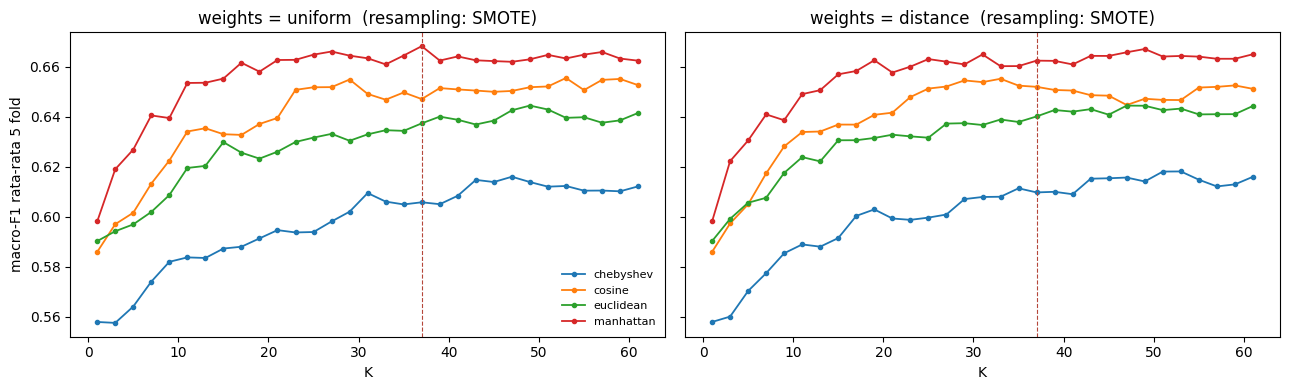

In [340]:
K_GRID = list(range(1, 62, 2))
rows = []
t0 = time.perf_counter()
for f, fold in enumerate(cv_folds):
    B, yb = fold["val"]
    for resampling in ("tanpa", "SMOTE"):
        A, ya = fold[resampling]
        for metric in ("euclidean", "manhattan", "chebyshev", "cosine"):
            m = KNNScratch(n_neighbors=max(K_GRID), metric=metric).fit(A, ya)
            dist, idx = m.kneighbors(B)
            labels = m.y_train_[idx]
            for k in K_GRID:
                for weights in ("uniform", "distance"):
                    pred = m.classes_[np.argmax(KNNScratch.vote(dist[:, :k], labels[:, :k], len(m.classes_), weights), axis=1)]
                    rows.append({"fold": f, "n_neighbors": k, "metric": metric, "weights": weights, "resampling": resampling,
                                 "macro_f1": sk_f1(yb, pred, average="macro"), "accuracy": sk_acc(yb, pred)})
knn_cv = (pd.DataFrame(rows).groupby(["n_neighbors", "metric", "weights", "resampling"])
          .agg(macro_f1=("macro_f1", "mean"), macro_f1_std=("macro_f1", "std"), accuracy=("accuracy", "mean"))
          .reset_index().sort_values(["macro_f1", "accuracy"], ascending=False).reset_index(drop=True))
print(f"{len(knn_cv)} konfigurasi x 5 fold dievaluasi dalam {time.perf_counter() - t0:.1f} detik")
display(knn_cv.head(10))
KNN_PARAMS = {"n_neighbors": int(knn_cv.loc[0, "n_neighbors"]), "metric": knn_cv.loc[0, "metric"], "weights": knn_cv.loc[0, "weights"]}
KNN_RESAMPLING = None if knn_cv.loc[0, "resampling"] == "tanpa" else knn_cv.loc[0, "resampling"]
print("KNN terbaik:", KNN_PARAMS, "| resampling:", KNN_RESAMPLING)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
sub = knn_cv[knn_cv["resampling"] == knn_cv.loc[0, "resampling"]]
for ax, w in zip(axes, ("uniform", "distance")):
    for metric, g in sub[sub["weights"] == w].groupby("metric"):
        g = g.sort_values("n_neighbors")
        ax.plot(g["n_neighbors"], g["macro_f1"], marker="o", ms=3, lw=1.3, label=metric)
    ax.axvline(KNN_PARAMS["n_neighbors"], color="#b5473a", lw=0.8, ls="--")
    ax.set_title(f"weights = {w}  (resampling: {knn_cv.loc[0, 'resampling']})")
    ax.set_xlabel("K")
axes[0].set_ylabel("macro-F1 rata-rata 5 fold")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

**Catatan**

* Sepuluh konfigurasi terbaik semuanya memakai jarak Manhattan dengan SMOTE. Manhattan menjumlahkan selisih tiap fitur tanpa dikuadratkan, jadi satu fitur yang selisihnya besar tidak langsung menguasai hasil. Ini cocok untuk data kami yang sebagian besar kolomnya hasil one-hot.
* Konfigurasi terbaik: K = 37, jarak Manhattan, voting sama rata, dengan SMOTE (macro-F1 CV 0,668 ± 0,020). Grafiknya cukup datar untuk K ≥ 25, jadi hasil tidak banyak berubah walaupun K sedikit digeser. K yang kecil (1 sampai 5) jelas lebih buruk karena hasilnya terlalu bergantung pada satu dua tetangga.
* SMOTE dipilih karena menaikkan recall kelas Enrolled, kelas yang paling sulit dan paling sedikit datanya (EDA 1.3.6). Akibatnya akurasi sedikit turun.

#### 2.3.3 Model KNN akhir, save dan load

In [341]:
path_knn = os.path.join(FOLDER_MODEL, "knn_scratch.pkl")
knn = ScratchPipeline(KNNScratch(**KNN_PARAMS), resampling=KNN_RESAMPLING).fit(x_train, y_train)
knn.save(path_knn)
knn_loaded = ScratchPipeline.load(path_knn)
assert np.array_equal(knn.predict(x_val), knn_loaded.predict(x_val))
assert np.array_equal(knn.predict_proba(x_val), knn_loaded.predict_proba(x_val))
print("KNN disimpan ke", path_knn, f"({os.path.getsize(path_knn) / 1024:.0f} KB); model yang dimuat ulang memberi prediksi identik")

pred_knn = knn.predict(x_val)
print("Akurasi validasi KNN:", round(np.mean(pred_knn == y_val.to_numpy()), 4))

KNN disimpan ke saved_models/knn_scratch.pkl (1975 KB); model yang dimuat ulang memberi prediksi identik
Akurasi validasi KNN: 0.7593


###2.4 Implementasi Logistic Regression

#### 2.4.1 Kelas `LogisticRegressionScratch`

Model dilatih dengan gradient descent untuk meminimalkan log-loss, sama seperti di materi kuliah. Ada dua cara menangani lebih dari dua kelas:

* Softmax (multinomial): P = softmax(XW + b). Yang diminimalkan adalah L = Σᵢ sᵢ · (−log P_{i,yᵢ}) + (α/2)‖W‖², dengan sᵢ bobot tiap sampel yang jumlahnya 1.
* One-vs-Rest: dibuat K model sigmoid biner, satu untuk tiap kelas. Hasil ketiganya dinormalisasi supaya jumlahnya 1.
* Untuk kedua cara, rumus gradiennya sama: ∂L/∂W = Xᵀ(s ⊙ (P − Y)) + αW dan ∂L/∂b = Σᵢ sᵢ(Pᵢ − Yᵢ). Bobot diperbarui dengan W ← W − η·∂L/∂W.
* Training berhenti kalau norma gradien sudah di bawah `tol` atau jumlah iterasi mencapai `max_iter`. Bias tidak ikut diregularisasi. Opsi `class_weight="balanced"` memberi bobot n / (K·n_c) untuk tiap kelas.
* Di scikit-learn, pengaturan ini setara dengan `C = 1 / (α·n)`.

In [342]:
def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def sigmoid(z):
    # tanh form avoids overflow in exp for large |z|.
    return 0.5 * (1.0 + np.tanh(0.5 * z))


def class_weights(y_enc, n_classes, mode):
    """Per-sample weights; 'balanced' uses n / (K * count_c) like scikit-learn."""
    if mode is None:
        return np.ones(len(y_enc))
    counts = np.bincount(y_enc, minlength=n_classes).astype(np.float64)
    if mode == "balanced":
        per_class = len(y_enc) / (n_classes * counts)
    else:
        per_class = np.array([mode[c] for c in range(n_classes)], dtype=np.float64)
    return per_class[y_enc]


class LogisticRegressionScratch(BaseClassifier):

    def __init__(self, learning_rate=0.1, max_iter=3000, alpha=1e-3, multi_class="softmax",
                 class_weight=None, tol=1e-5, fit_intercept=True, random_state=None):
        if multi_class not in ("softmax", "ovr"):
            raise ValueError("multi_class must be 'softmax' or 'ovr'")
        if learning_rate <= 0:
            raise ValueError("learning_rate must be positive")
        self.learning_rate = learning_rate
        self.max_iter = max_iter
        self.alpha = alpha
        self.multi_class = multi_class
        self.class_weight = class_weight
        self.tol = tol
        self.fit_intercept = fit_intercept
        self.random_state = random_state

    def _forward(self, X, W, b):
        Z = X @ W + b
        return softmax(Z) if self.multi_class == "softmax" else sigmoid(Z)

    def _loss_and_grads(self, X, Y, sw, W, b):
        """Objective value and its gradients; sw are per-sample weights that sum to 1."""
        P = self._forward(X, W, b)
        if self.multi_class == "softmax":
            loss = -np.sum(sw * np.log(np.clip(np.sum(P * Y, axis=1), 1e-15, None)))
        else:
            Pc = np.clip(P, 1e-15, 1 - 1e-15)
            loss = -np.sum(sw[:, None] * (Y * np.log(Pc) + (1 - Y) * np.log(1 - Pc)))
        loss += 0.5 * self.alpha * np.sum(W * W)
        G = sw[:, None] * (P - Y)
        dW = X.T @ G + self.alpha * W
        db = G.sum(axis=0) if self.fit_intercept else np.zeros_like(b)
        return loss, dW, db

    def fit(self, X, y):
        X = check_array(X)
        y_enc = self._encode_labels(y)
        n, d = X.shape
        K = len(self.classes_)
        self.n_features_in_ = d
        sw = class_weights(y_enc, K, self.class_weight)
        sw = sw / sw.sum()
        Y = np.zeros((n, K))
        Y[np.arange(n), y_enc] = 1.0

        rng = np.random.default_rng(self.random_state)
        W = rng.normal(0.0, 0.01, size=(d, K))
        b = np.zeros(K)
        self.loss_history_, self.grad_norm_history_ = [], []
        self.converged_ = False
        it = -1
        for it in range(self.max_iter):
            loss, dW, db = self._loss_and_grads(X, Y, sw, W, b)
            grad_norm = float(np.sqrt(np.sum(dW * dW) + np.sum(db * db)))
            self.loss_history_.append(float(loss))
            self.grad_norm_history_.append(grad_norm)
            if grad_norm < self.tol:
                self.converged_ = True
                break
            W -= self.learning_rate * dW
            b -= self.learning_rate * db
        self.coef_ = W
        self.intercept_ = b
        self.n_iter_ = it + 1
        return self

    def decision_function(self, X):
        X = check_array(X)
        if X.shape[1] != self.n_features_in_:
            raise ValueError(f"expected {self.n_features_in_} features, got {X.shape[1]}")
        return X @ self.coef_ + self.intercept_

    def predict_proba(self, X):
        Z = self.decision_function(X)
        if self.multi_class == "softmax":
            return softmax(Z)
        P = sigmoid(Z)
        return P / P.sum(axis=1, keepdims=True)

#### 2.4.2 Laju belajar dan konvergensi

Sebelum tuning, kami cek dulu beberapa laju belajar di fold pertama (α = 0,001).

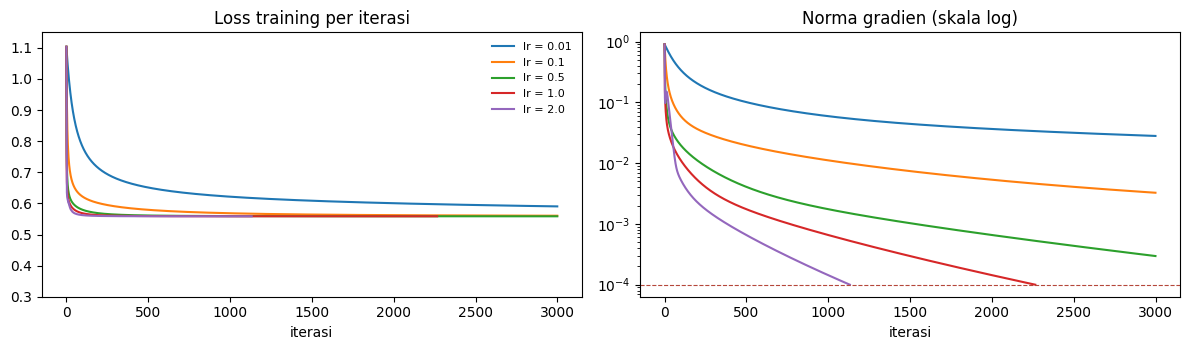

,learning_rate,iterasi,konvergen,loss_akhir,macro_f1_fold
0,0.01,3000,False,0.590406,0.657425
1,0.10,3000,False,0.560442,0.670806
2,0.50,3000,False,0.558551,0.686260
3,1.00,2266,True,0.558524,0.686260
4,2.00,1133,True,0.558524,0.686260


Laju belajar dipakai: 2.0


In [343]:
A, ya = cv_folds[0]["tanpa"]
B, yb = cv_folds[0]["val"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
lr_rows = []
for lr in (0.01, 0.1, 0.5, 1.0, 2.0):
    m = LogisticRegressionScratch(learning_rate=lr, max_iter=3000, alpha=1e-3, tol=1e-4, random_state=SEED).fit(A, ya)
    axes[0].plot(m.loss_history_, label=f"lr = {lr}")
    axes[1].semilogy(m.grad_norm_history_, label=f"lr = {lr}")
    lr_rows.append({"learning_rate": lr, "iterasi": m.n_iter_, "konvergen": m.converged_, "loss_akhir": m.loss_history_[-1],
                    "macro_f1_fold": sk_f1(yb, m.predict(B), average="macro")})
axes[0].set_title("Loss training per iterasi"); axes[0].set_xlabel("iterasi"); axes[0].set_ylim(0.3, 1.15)
axes[1].set_title("Norma gradien (skala log)"); axes[1].set_xlabel("iterasi")
axes[1].axhline(1e-4, color="#b5473a", lw=0.8, ls="--")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()
lr_table = pd.DataFrame(lr_rows)
display(lr_table)
stable = lr_table[np.isfinite(lr_table["loss_akhir"])]
# Pilih yang konvergen paling cepat; jika tidak ada, yang loss akhirnya terendah.
LR_RATE = float(stable.sort_values(["konvergen", "iterasi", "loss_akhir"], ascending=[False, True, True])["learning_rate"].iloc[0])
print("Laju belajar dipakai:", LR_RATE)

**Catatan**

* Laju belajar 0,01 terlalu lambat, loss-nya masih tinggi setelah 3.000 iterasi. Laju 1,0 dan 2,0 sampai di loss akhir yang sama dan konvergen (norma gradien < 1e-4). Laju 2,0 paling cepat (1.133 iterasi) dan tidak berosilasi, karena fiturnya sudah distandardisasi.

#### 2.4.3 Tuning Logistic Regression dengan 5-fold cross-validation

Kombinasi yang dicoba: α ∈ {0, 1e-4, 1e-3, 1e-2, 1e-1}, softmax atau one-vs-rest, dan tiga cara menangani ketidakseimbangan (tanpa penanganan, `class_weight="balanced"`, atau SMOTE di fold latih).

In [344]:
rows = []
t0 = time.perf_counter()
for f, fold in enumerate(cv_folds):
    B, yb = fold["val"]
    for alpha in (0.0, 1e-4, 1e-3, 1e-2, 1e-1):
        for multi_class in ("softmax", "ovr"):
            for balancing in ("tanpa", "balanced", "SMOTE"):
                A, ya = fold["SMOTE" if balancing == "SMOTE" else "tanpa"]
                m = LogisticRegressionScratch(learning_rate=LR_RATE, max_iter=3000, tol=1e-4, alpha=alpha, multi_class=multi_class,
                                              class_weight="balanced" if balancing == "balanced" else None,
                                              random_state=SEED).fit(A, ya)
                pred = m.predict(B)
                rows.append({"fold": f, "alpha": alpha, "multi_class": multi_class, "balancing": balancing,
                             "macro_f1": sk_f1(yb, pred, average="macro"), "accuracy": sk_acc(yb, pred),
                             "recall_Enrolled": np.mean(pred[yb == 1] == 1), "converged": m.converged_})
lr_cv = (pd.DataFrame(rows).groupby(["alpha", "multi_class", "balancing"])
         .agg(macro_f1=("macro_f1", "mean"), macro_f1_std=("macro_f1", "std"), accuracy=("accuracy", "mean"),
              recall_Enrolled=("recall_Enrolled", "mean"), converged=("converged", "mean"))
         .reset_index().sort_values(["macro_f1", "accuracy"], ascending=False).reset_index(drop=True))
print(f"{len(lr_cv)} konfigurasi x 5 fold dievaluasi dalam {time.perf_counter() - t0:.0f} detik")
display(lr_cv.head(10))
best = lr_cv.loc[0]
LR_PARAMS = {"alpha": float(best["alpha"]), "multi_class": best["multi_class"],
             "class_weight": "balanced" if best["balancing"] == "balanced" else None}
LR_RESAMPLING = "SMOTE" if best["balancing"] == "SMOTE" else None
print("Logistic Regression terbaik:", LR_PARAMS, "| resampling:", LR_RESAMPLING)
display(lr_cv.groupby("balancing")[["macro_f1", "accuracy", "recall_Enrolled"]].max())

30 konfigurasi x 5 fold dievaluasi dalam 404 detik


,alpha,multi_class,balancing,macro_f1,macro_f1_std,accuracy,recall_Enrolled,converged
0,0.0100,ovr,SMOTE,0.697867,0.019555,0.742014,0.584270,1.0
1,0.0100,ovr,balanced,0.693102,0.016270,0.739189,0.566292,1.0
2,0.0001,softmax,balanced,0.692527,0.026233,0.735548,0.586517,0.0
3,0.0010,ovr,SMOTE,0.692467,0.017544,0.739185,0.552809,1.0
4,0.0001,ovr,balanced,0.691351,0.019939,0.738376,0.552809,0.0
5,0.0010,softmax,balanced,0.691144,0.026374,0.733931,0.591011,0.0
6,0.0000,ovr,balanced,0.691103,0.017084,0.737973,0.552809,0.0
7,0.0000,softmax,balanced,0.690417,0.027329,0.734336,0.577528,0.0
8,0.0001,softmax,SMOTE,0.687524,0.030157,0.731918,0.559551,0.0
9,0.0001,ovr,SMOTE,0.687058,0.019833,0.735956,0.530337,0.0


Logistic Regression terbaik: {'alpha': 0.01, 'multi_class': 'ovr', 'class_weight': None} | resampling: SMOTE


,macro_f1,accuracy,recall_Enrolled
balancing,,,
SMOTE,0.697867,0.742014,0.588764
balanced,0.693102,0.739189,0.591011
tanpa,0.662552,0.756954,0.303371


**Catatan**

* Konfigurasi terbaik: one-vs-rest, α = 0,01, dengan SMOTE (macro-F1 CV 0,698 ± 0,020).
* Penanganan ketidakseimbangan sangat berpengaruh. Tanpa penanganan, akurasi CV paling tinggi (0,757), tapi recall Enrolled hanya 0,30 dan macro-F1 turun ke 0,663. Dengan SMOTE atau `class_weight="balanced"`, recall Enrolled naik ke sekitar 0,59 dan macro-F1 sekitar 0,69 sampai 0,70.
* Beberapa konfigurasi softmax dengan α kecil belum mencapai toleransi 1e-4 dalam 3.000 iterasi (lihat kolom `converged`). Karena itu model akhir dilatih dengan batas iterasi yang jauh lebih besar.

#### 2.4.4 Model Logistic Regression akhir, save dan load

Model akhir dilatih sampai norma gradien di bawah 1e-4, dengan batas 30.000 iterasi. Saat tuning batasnya hanya 3.000 iterasi supaya semua kombinasi bisa selesai dalam waktu wajar.

In [345]:
path_logreg = os.path.join(FOLDER_MODEL, "logreg_scratch.pkl")
logreg = ScratchPipeline(LogisticRegressionScratch(learning_rate=LR_RATE, max_iter=30000, tol=1e-4, random_state=SEED, **LR_PARAMS),
                         resampling=LR_RESAMPLING).fit(x_train, y_train)
print(f"Konvergen: {logreg.model.converged_} setelah {logreg.model.n_iter_} iterasi (norma gradien akhir {logreg.model.grad_norm_history_[-1]:.2e})")
logreg.save(path_logreg)
logreg_loaded = ScratchPipeline.load(path_logreg)
assert np.array_equal(logreg.predict(x_val), logreg_loaded.predict(x_val))
assert np.array_equal(logreg.predict_proba(x_val), logreg_loaded.predict_proba(x_val))
print("Logistic Regression disimpan ke", path_logreg, "; model yang dimuat ulang memberi prediksi identik")

pred_logreg = logreg.predict(x_val)
print("Akurasi validasi Logistic Regression:", round(np.mean(pred_logreg == y_val.to_numpy()), 4))

Konvergen: True setelah 319 iterasi (norma gradien akhir 9.93e-05)
Logistic Regression disimpan ke saved_models/logreg_scratch.pkl ; model yang dimuat ulang memberi prediksi identik
Akurasi validasi Logistic Regression: 0.7625


#### 2.4.5 Interpretasi koefisien

Karena fitur numerik sudah distandardisasi, besar koefisiennya bisa dibandingkan antar-fitur. Pada softmax yang bermakna hanya selisih koefisien antar-kelas, jadi koefisien tiap fitur dikurangi rata-ratanya di ketiga kelas.

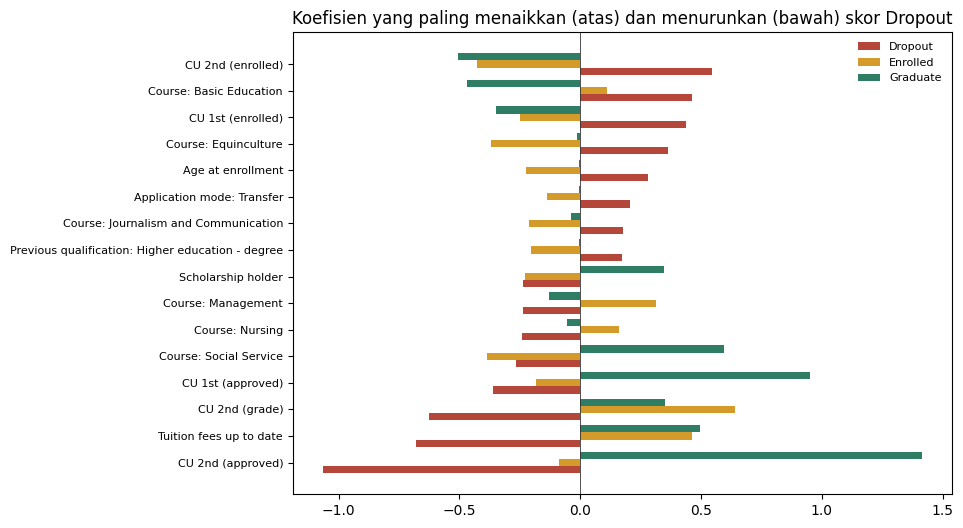

In [346]:
def pretty(name):
    col, _, code_ = name.partition("=")
    if code_:
        label = eda_labels.get(col, {}).get(int(float(code_)))
        return f"{col}: {label[:36]}" if label else name
    return short(name)


W = logreg.model.coef_
W = W - W.mean(axis=1, keepdims=True) if LR_PARAMS["multi_class"] == "softmax" else W
coef = pd.DataFrame(W, index=[pretty(f) for f in logreg.pre_.feature_names_], columns=KELAS)
top = coef.reindex(coef["Dropout"].sort_values().index)
top = pd.concat([top.head(8), top.tail(8)])
fig, ax = plt.subplots(figsize=(8.5, 6))
yy = np.arange(len(top))
for j, k in enumerate(KELAS):
    ax.barh(yy + (j - 1) * 0.27, top[k], height=0.27, color=EDA_COLORS[k], label=k)
ax.set_yticks(yy, top.index, fontsize=8)
ax.axvline(0, color="#333", lw=0.6)
ax.set_title("Koefisien yang paling menaikkan (atas) dan menurunkan (bawah) skor Dropout")
ax.legend(frameon=False, fontsize=8)
plt.show()

**Catatan**

* Pada One-vs-Rest, tiap kolom adalah model biner untuk satu kelas. Fitur yang paling menurunkan peluang Dropout adalah jumlah mata kuliah lulus di semester 2, SPP yang lancar, dan nilai semester 2. Hasil ini cocok dengan uji statistik di EDA 1.3.7 dan 1.3.8.
* Fitur yang paling menaikkan peluang Dropout adalah jumlah mata kuliah yang diambil, beberapa prodi (Basic Education dan Equinculture, yang di EDA memang tinggi Dropout-nya), dan umur saat masuk. Untuk jumlah mata kuliah yang diambil, maksudnya: kalau jumlah lulusnya sama, mahasiswa yang mengambil lebih banyak mata kuliah berarti lebih banyak yang gagal, dan itu tanda risiko.
* Karena fitur-fiturnya saling berkorelasi (VIF sampai 23,6, EDA 1.3.9), koefisien satu fitur tidak boleh dibaca sebagai sebab-akibat.

###2.5 Implementasi Artificial Neural Network (ANN)

In [347]:
class Ann():
  def __init__(self, hidden_size=32, epochs=2000, learning_rate=0.1, seed=42, verbose=True):
      self.hidden_size = hidden_size
      self.epochs = epochs
      self.learning_rate = learning_rate
      self.seed = seed
      self.verbose = verbose
      self.parameters = None
      self.mean = None
      self.std = None
      self.n_kelas = None
      self.cost_history = []

  def sigmoid(self, Z):
    return 1 / (1 + np.exp(-Z))

  def relu(self, Z):
      return np.maximum(0, Z)

  def relu_derivative(self, Z):
      return (Z > 0).astype(float)

  def standardisasi(self, X):
      X = np.asarray(X, dtype=float)
      return ((X - self.mean) / self.std).T

  def one_hot(self, y):
      Y = np.zeros((self.n_kelas, len(y)))
      Y[y, np.arange(len(y))] = 1
      return Y

  def initialize_parameters(self, input_size, hidden_size, output_size):
    np.random.seed(self.seed)
    parameters = {
        "W1": np.random.randn(hidden_size, input_size) * 0.01,
        "b1": np.zeros((hidden_size, 1)),
        "W2": np.random.randn(output_size, hidden_size) * 0.01,
        "b2": np.zeros((output_size, 1))
    }
    return parameters

  def forward_propagation(self, X, parameters):
      W1, b1, W2, b2 = parameters["W1"], parameters["b1"], parameters["W2"], parameters["b2"]

      Z1 = np.dot(W1, X) + b1
      A1 = self.relu(Z1)
      Z2 = np.dot(W2, A1) + b2
      A2 = self.sigmoid(Z2)

      cache = {"Z1": Z1, "A1": A1, "Z2": Z2, "A2": A2}
      return A2, cache

  def compute_cost(self, Y, A2):
      m = Y.shape[1]
      A2 = np.clip(A2, 1e-12, 1 - 1e-12)
      cost = -np.sum(Y * np.log(A2) + (1 - Y) * np.log(1 - A2)) / m   # binary cross-entropy
      return np.squeeze(cost)

  def backward_propagation(self, X, Y, parameters, cache):
      m = X.shape[1]
      W2 = parameters["W2"]

      dZ2 = cache["A2"] - Y
      dW2 = np.dot(dZ2, cache["A1"].T) / m
      db2 = np.sum(dZ2, axis=1, keepdims=True) / m

      dZ1 = np.dot(W2.T, dZ2) * self.relu_derivative(cache["Z1"])
      dW1 = np.dot(dZ1, X.T) / m
      db1 = np.sum(dZ1, axis=1, keepdims=True) / m

      grads = {"dW1": dW1, "db1": db1, "dW2": dW2, "db2": db2}
      return grads

  def update_parameters(self, parameters, grads):
      for key in parameters.keys():
          parameters[key] -= self.learning_rate * grads["d" + key]
      return parameters

  def fit(self, X, y):
      X_arr = np.asarray(X, dtype=float)
      y = np.asarray(y).astype(int)

      # simpan mean & std data latih (dipakai lagi saat predict)
      self.mean = X_arr.mean(axis=0)
      self.std = X_arr.std(axis=0)
      self.std[self.std == 0] = 1
      self.n_kelas = int(y.max()) + 1

      X_t = self.standardisasi(X_arr)
      Y = self.one_hot(y)
      self.parameters = self.initialize_parameters(X_t.shape[0], self.hidden_size, self.n_kelas)
      self.cost_history = []

      for i in range(self.epochs):
          A2, cache = self.forward_propagation(X_t, self.parameters)
          cost = self.compute_cost(Y, A2)
          grads = self.backward_propagation(X_t, Y, self.parameters, cache)
          self.parameters = self.update_parameters(self.parameters, grads)
          self.cost_history.append(cost)

          if self.verbose and i % 200 == 0:
              print(f"Epoch {i}: Cost = {cost:.4f}")
      return self

  def predict_proba(self, X):
      A2, cache = self.forward_propagation(self.standardisasi(X), self.parameters)
      return A2.T

  def predict(self, X):
      return np.argmax(self.predict_proba(X), axis=1)

  def save_to_pickle(self, path):
      with open(path, "wb") as f:
          pickle.dump(self.__dict__, f)

  def load_from_pickle(self, path):
      with open(path, "rb") as f:
          self.__dict__.update(pickle.load(f))


In [348]:
os.makedirs("saved_models", exist_ok=True)
path_ann = "saved_models/ann.pkl"
ulang = True
ann = Ann(hidden_size=32, epochs=2000, learning_rate=0.1)
if os.path.exists(path_ann) and ulang==False:
    ann.load_from_pickle(path_ann)
    print("ANN dimuat dari", path_ann)
else:
    ann.fit(x_train, y_train)
    ann.save_to_pickle(path_ann)
    print("ANN dilatih dan disimpan ke", path_ann)

pred_ann = ann.predict(x_val)
print("Akurasi validasi ANN:", round(np.mean(pred_ann == y_val.to_numpy()), 4))

Epoch 0: Cost = 2.0797
Epoch 200: Cost = 1.1268
Epoch 400: Cost = 1.0670
Epoch 600: Cost = 1.0417
Epoch 800: Cost = 1.0302
Epoch 1000: Cost = 1.0211
Epoch 1200: Cost = 1.0126
Epoch 1400: Cost = 1.0052
Epoch 1600: Cost = 0.9989
Epoch 1800: Cost = 0.9928
ANN dilatih dan disimpan ke saved_models/ann.pkl
Akurasi validasi ANN: 0.7997


###2.6 Implementasi Ensemble (Majority Voting, Weighted Voting, Soft Voting)

In [368]:
semua_pred = [pred_dtl, pred_rf, pred_knn, pred_logreg, pred_ann]

bobot = []
for pred in semua_pred:
    bobot.append(np.mean(pred == y_val.to_numpy()))


def hard_voting(semua_pred):
    hasil = []
    for i in range(len(semua_pred[0])):
        suara = [0, 0, 0]
        for pred in semua_pred:
            kelas = int(pred[i])
            suara[kelas] = suara[kelas] + 1
        hasil.append(suara.index(max(suara)))
    return np.array(hasil)


def weighted_voting(semua_pred, bobot):
    hasil = []
    for i in range(len(semua_pred[0])):
        suara = [0, 0, 0]
        for j in range(len(semua_pred)):
            kelas = int(semua_pred[j][i])
            suara[kelas] = suara[kelas] + bobot[j]
        hasil.append(suara.index(max(suara)))
    return np.array(hasil)


def soft_voting(semua_proba):
    hasil = []
    for i in range(len(semua_proba[0])):
        total = [0, 0, 0]
        for proba in semua_proba:
            for kelas in range(3):
                total[kelas] = total[kelas] + proba[i][kelas]
        hasil.append(total.index(max(total)))
    return np.array(hasil)


def ubah_ke_proba(pred):
    semua_proba = []
    for kelas in pred:
        proba = [0, 0, 0]
        proba[int(kelas)] = 1
        semua_proba.append(proba)
    return semua_proba


proba_ann = ann.predict_proba(x_val)
proba_ann = proba_ann / proba_ann.sum(axis=1, keepdims=True)

semua_proba = [ubah_ke_proba(pred_dtl), ubah_ke_proba(pred_rf),
               knn.predict_proba(x_val), logreg.predict_proba(x_val), proba_ann]

pred_hard = hard_voting(semua_pred)
pred_weighted = weighted_voting(semua_pred, bobot)
pred_soft = soft_voting(semua_proba)

print("Bobot:", np.round(bobot, 4))
print("Akurasi:")
print("Hard     :", np.mean(pred_hard == y_val.to_numpy()))
print("Weighted :", np.mean(pred_weighted == y_val.to_numpy()))
print("Soft     :", np.mean(pred_soft == y_val.to_numpy()))

Bobot: [0.7189 0.7658 0.7593 0.7625 0.7997]
Akurasi:
Hard     : 0.802907915993538
Weighted : 0.8061389337641357
Soft     : 0.778675282714055


##3. ScikitLearn

###3.1 ScikitLearn Preprocessing

In [350]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score


y_tr = np.asarray(y_train).astype(int)
y_va = np.asarray(y_val).astype(int)

kolom_nominal = ["Application mode", "Course", "Previous qualification"]
kolom_numerik = [c for c in x_train.columns if c not in kolom_nominal]

def buat_preprocessor():
    return ColumnTransformer([
        ("nominal", OneHotEncoder(handle_unknown="ignore"), kolom_nominal),
        ("numerik", StandardScaler(), kolom_numerik),
    ])

# validasi silang 5-fold di data latih untuk memilih hyperparameter
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
hasil_sklearn = []

###3.2 ScikitLearn DTL

,Nilai (macro)
Accuracy,0.7593
Precision,0.7237
Recall,0.6489
F1-score,0.6552


              precision    recall  f1-score   support

     Dropout       0.82      0.77      0.80       199
    Enrolled       0.60      0.23      0.34       111
    Graduate       0.75      0.94      0.83       309

    accuracy                           0.76       619
   macro avg       0.72      0.65      0.66       619
weighted avg       0.74      0.76      0.73       619



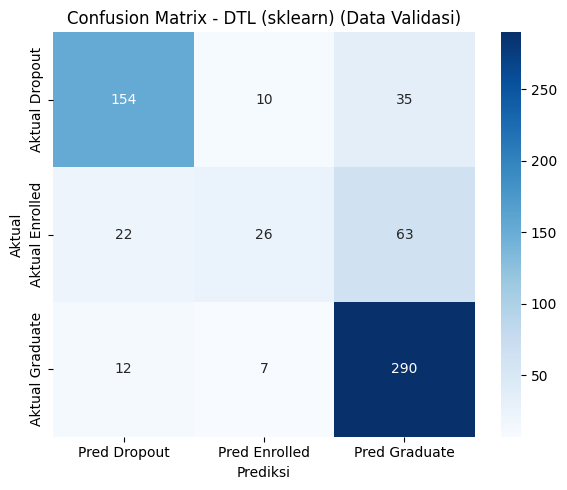

In [351]:
from sklearn.tree import DecisionTreeClassifier as SkDecisionTree

sk_dtl = SkDecisionTree(criterion="entropy", max_depth=5, min_samples_leaf=5, random_state=42)
sk_dtl.fit(x_train, y_tr)
pred_sk_dtl = sk_dtl.predict(x_val)
hasil_sklearn.append(model_eval(y_va, pred_sk_dtl, "DTL (sklearn)"))

###3.3 ScikitLearn Random Forest

,Nilai (macro)
Accuracy,0.7851
Precision,0.8021
Recall,0.6673
F1-score,0.6786


              precision    recall  f1-score   support

     Dropout       0.87      0.78      0.83       199
    Enrolled       0.79      0.23      0.36       111
    Graduate       0.75      0.98      0.85       309

    accuracy                           0.79       619
   macro avg       0.80      0.67      0.68       619
weighted avg       0.79      0.79      0.75       619



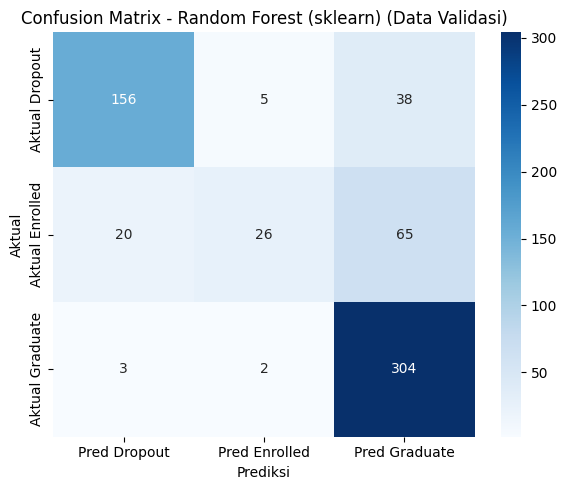

In [352]:
from sklearn.ensemble import RandomForestClassifier as SkRandomForest

sk_rf = SkRandomForest(n_estimators=30, criterion="entropy", max_depth=5,
                       min_samples_leaf=5, max_features=4, random_state=42)
sk_rf.fit(x_train, y_tr)
pred_sk_rf = sk_rf.predict(x_val)
hasil_sklearn.append(model_eval(y_va, pred_sk_rf, "Random Forest (sklearn)"))

###3.4 ScikitLearn K-Nearest Neighbors

Parameter terbaik KNN: {'kneighborsclassifier__n_neighbors': 11, 'kneighborsclassifier__weights': 'uniform'}


,Nilai (macro)
Accuracy,0.7674
Precision,0.7260
Recall,0.6738
F1-score,0.6865


              precision    recall  f1-score   support

     Dropout       0.83      0.74      0.79       199
    Enrolled       0.58      0.34      0.43       111
    Graduate       0.77      0.94      0.85       309

    accuracy                           0.77       619
   macro avg       0.73      0.67      0.69       619
weighted avg       0.76      0.77      0.75       619



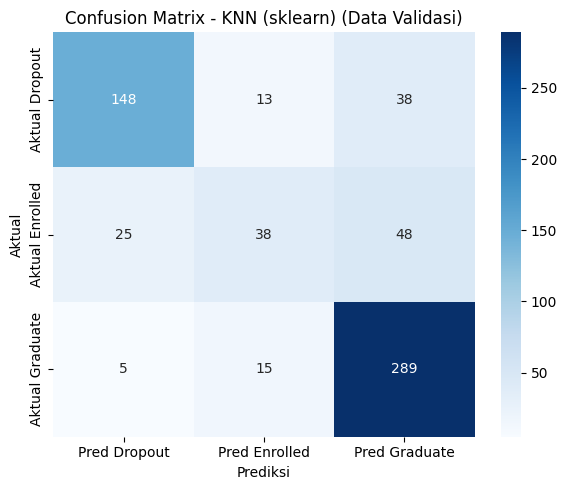

In [371]:
from sklearn.neighbors import KNeighborsClassifier

# KNN butuh fitur berskala sama -> pakai preprocessor
knn_search = GridSearchCV(
    make_pipeline(buat_preprocessor(), KNeighborsClassifier()),
    {"kneighborsclassifier__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
     "kneighborsclassifier__weights": ["uniform", "distance"]},
    scoring="f1_macro", cv=cv)
knn_search.fit(x_train, y_tr)
print("Parameter terbaik KNN:", knn_search.best_params_)

sk_knn = knn_search.best_estimator_
pred_sk_knn = sk_knn.predict(x_val)
hasil_sklearn.append(model_eval(y_va, pred_sk_knn, "KNN (sklearn)"))

###3.5 ScikitLearn Logistic Regression

Parameter terbaik Logistic Regression: {'logisticregression__C': 10}


,Nilai (macro)
Accuracy,0.8142
Precision,0.7967
Recall,0.7362
F1-score,0.7541


              precision    recall  f1-score   support

     Dropout       0.82      0.78      0.80       199
    Enrolled       0.74      0.47      0.57       111
    Graduate       0.82      0.96      0.89       309

    accuracy                           0.81       619
   macro avg       0.80      0.74      0.75       619
weighted avg       0.81      0.81      0.80       619



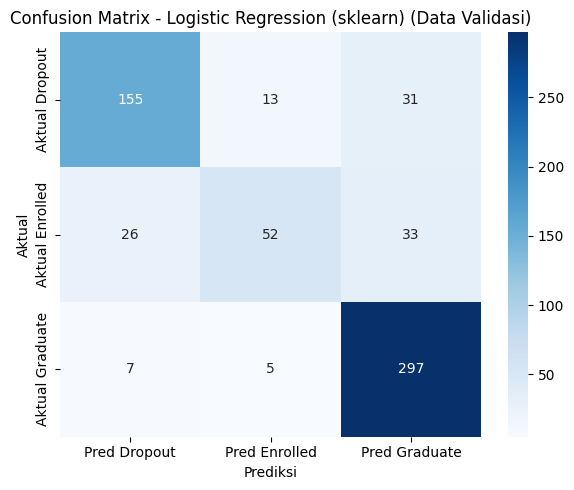

In [372]:
from sklearn.linear_model import LogisticRegression

lr_search = GridSearchCV(
    make_pipeline(buat_preprocessor(), LogisticRegression(max_iter=2000)),
    {"logisticregression__C": [0.01, 0.1, 1, 10, 100]},
    scoring="f1_macro", cv=cv)
lr_search.fit(x_train, y_tr)
print("Parameter terbaik Logistic Regression:", lr_search.best_params_)

sk_lr = lr_search.best_estimator_
pred_sk_lr = sk_lr.predict(x_val)
hasil_sklearn.append(model_eval(y_va, pred_sk_lr, "Logistic Regression (sklearn)"))

###3.5 ScikitLearn Artificial Neural Network (ANN)

,Nilai (macro)
Accuracy,0.8158
Precision,0.7941
Recall,0.7339
F1-score,0.7508


              precision    recall  f1-score   support

     Dropout       0.84      0.80      0.82       199
    Enrolled       0.72      0.44      0.55       111
    Graduate       0.82      0.96      0.89       309

    accuracy                           0.82       619
   macro avg       0.79      0.73      0.75       619
weighted avg       0.81      0.82      0.80       619



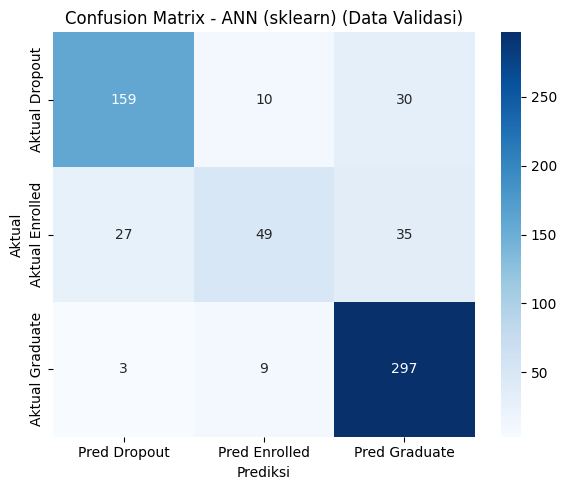

In [355]:
from sklearn.neural_network import MLPClassifier

sk_ann = make_pipeline(
    buat_preprocessor(),
    MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu", alpha=1e-3,
                  early_stopping=True, max_iter=500, random_state=42))
sk_ann.fit(x_train, y_tr)
pred_sk_ann = sk_ann.predict(x_val)
hasil_sklearn.append(model_eval(y_va, pred_sk_ann, "ANN (sklearn)"))

###3.6 ScikitLearn Ensemble

Bobot: [0.619 0.62  0.633 0.661 0.666]


,Nilai (macro)
Accuracy,0.8061
Precision,0.7938
Recall,0.7083
F1-score,0.7256


              precision    recall  f1-score   support

     Dropout       0.84      0.78      0.81       199
    Enrolled       0.74      0.36      0.48       111
    Graduate       0.80      0.98      0.88       309

    accuracy                           0.81       619
   macro avg       0.79      0.71      0.73       619
weighted avg       0.80      0.81      0.79       619



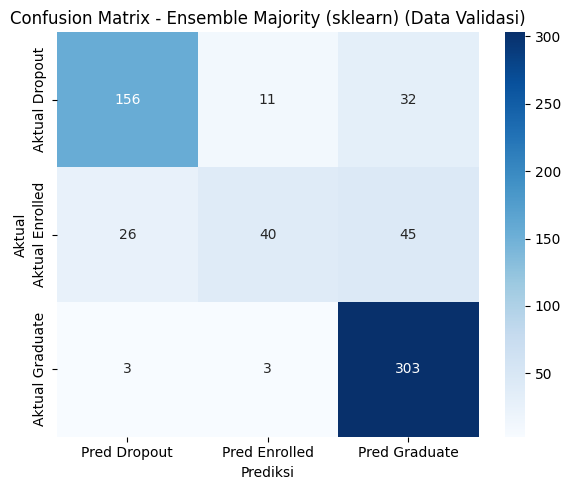

,Nilai (macro)
Accuracy,0.8061
Precision,0.7922
Recall,0.7096
F1-score,0.7274


              precision    recall  f1-score   support

     Dropout       0.85      0.78      0.81       199
    Enrolled       0.73      0.37      0.49       111
    Graduate       0.80      0.98      0.88       309

    accuracy                           0.81       619
   macro avg       0.79      0.71      0.73       619
weighted avg       0.80      0.81      0.79       619



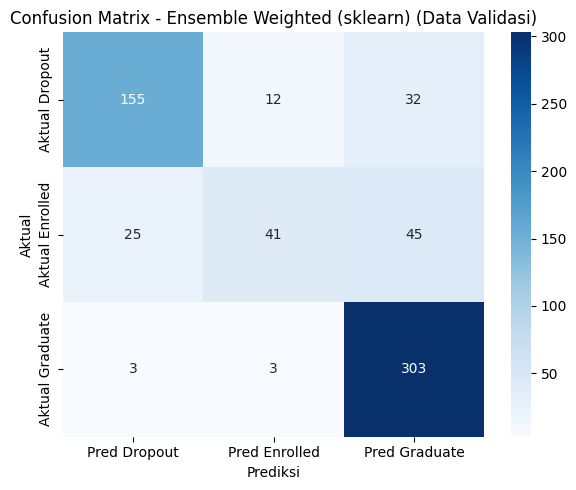

,Nilai (macro)
Accuracy,0.8142
Precision,0.8057
Recall,0.7206
F1-score,0.7400


              precision    recall  f1-score   support

     Dropout       0.86      0.79      0.83       199
    Enrolled       0.75      0.39      0.51       111
    Graduate       0.80      0.98      0.88       309

    accuracy                           0.81       619
   macro avg       0.81      0.72      0.74       619
weighted avg       0.81      0.81      0.80       619



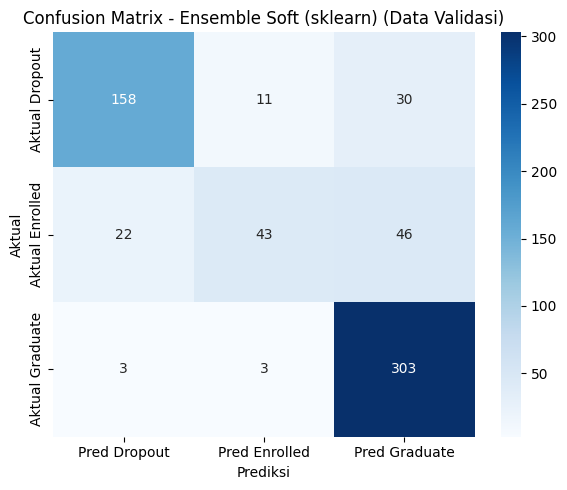

In [373]:
from sklearn.ensemble import VotingClassifier
from sklearn.tree import DecisionTreeClassifier as SkDecisionTree
from sklearn.ensemble import RandomForestClassifier as SkRandomForest
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score

model1 = SkDecisionTree(criterion="entropy", max_depth=6, min_samples_leaf=5, random_state=42)
model2 = SkRandomForest(n_estimators=100, criterion="entropy", max_depth=6, min_samples_leaf=5, random_state=42)
model3 = make_pipeline(buat_preprocessor(), KNeighborsClassifier(n_neighbors=11))
model4 = make_pipeline(buat_preprocessor(), LogisticRegression(max_iter=1000))
model5 = make_pipeline(buat_preprocessor(),
                       MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu", alpha=1e-3,
                                     early_stopping=True, max_iter=500, random_state=42))

# bobot = macro-F1 validasi silang di data latih
bobot = [
    cross_val_score(model1, x_train, y_tr, cv=cv, scoring="f1_macro").mean(),
    cross_val_score(model2, x_train, y_tr, cv=cv, scoring="f1_macro").mean(),
    cross_val_score(model3, x_train, y_tr, cv=cv, scoring="f1_macro").mean(),
    cross_val_score(model4, x_train, y_tr, cv=cv, scoring="f1_macro").mean(),
    cross_val_score(model5, x_train, y_tr, cv=cv, scoring="f1_macro").mean(),
]
print("Bobot:", np.round(bobot, 3))

ensemble_hard = VotingClassifier(
    estimators = [
        ("dtl", model1),
        ("rf", model2),
        ("knn", model3),
        ("logreg", model4),
        ("ann", model5)
    ],
    voting = "hard"
)

ensemble_soft = VotingClassifier(
    estimators = [
        ("dtl", model1),
        ("rf", model2),
        ("knn", model3),
        ("logreg", model4),
        ("ann", model5)
    ],
    voting = "soft"
)

ensemble_weighted = VotingClassifier(
    estimators = [
        ("dtl", model1),
        ("rf", model2),
        ("knn", model3),
        ("logreg", model4),
        ("ann", model5)
    ],
    voting = "hard",
    weights = bobot
)

# Majority (hard) voting
ensemble_hard.fit(x_train, y_tr)
pred_sk_ensemble_hard = ensemble_hard.predict(x_val)
hasil_sklearn.append(model_eval(y_va, pred_sk_ensemble_hard, "Ensemble Majority (sklearn)"))

# Weighted voting
ensemble_weighted.fit(x_train, y_tr)
pred_sk_ensemble_weighted = ensemble_weighted.predict(x_val)
hasil_sklearn.append(model_eval(y_va, pred_sk_ensemble_weighted, "Ensemble Weighted (sklearn)"))

# Soft voting
ensemble_soft.fit(x_train, y_tr)
pred_sk_ensemble_soft = ensemble_soft.predict(x_val)
hasil_sklearn.append(model_eval(y_va, pred_sk_ensemble_soft, "Ensemble Soft (sklearn)"))

##4. Evaluasi Hasil Implementasi
Evaluasi: accuracy, precision, recall, F1, confusion matrix serta perbandingan dengan Hasil ScikitLearn

In [357]:
hasil_scratch = {}

def bandingkan(metrik_scratch, nama_sklearn):
    sk = {s.name: s for s in hasil_sklearn}
    tabel = pd.concat([metrik_scratch, sk[nama_sklearn]], axis=1)
    tabel["Selisih (scratch - sklearn)"] = (tabel.iloc[:, 0] - tabel.iloc[:, 1]).round(4)
    display(tabel)

###4.1 Evaluasi DTL

,Nilai (macro)
Accuracy,0.7189
Precision,0.6535
Recall,0.6384
F1-score,0.6436


              precision    recall  f1-score   support

     Dropout       0.74      0.65      0.69       199
    Enrolled       0.43      0.38      0.40       111
    Graduate       0.79      0.88      0.83       309

    accuracy                           0.72       619
   macro avg       0.65      0.64      0.64       619
weighted avg       0.71      0.72      0.71       619



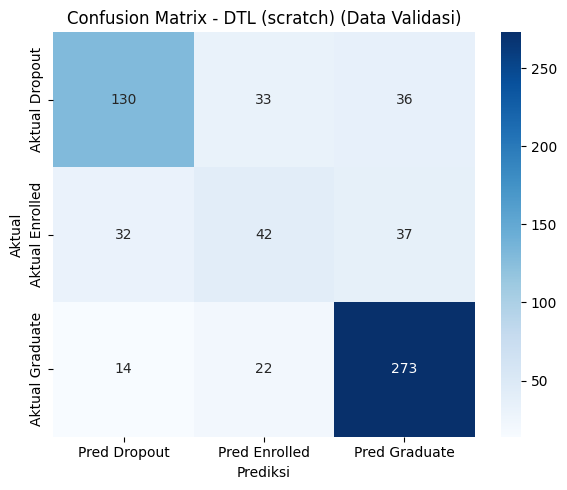

,DTL (scratch),DTL (sklearn),Selisih (scratch - sklearn)
Accuracy,0.7189,0.7593,-0.0404
Precision,0.6535,0.7237,-0.0702
Recall,0.6384,0.6489,-0.0105
F1-score,0.6436,0.6552,-0.0116


In [358]:
hasil_scratch["DTL"] = model_eval(y_val, pred_dtl, "DTL (scratch)")
bandingkan(hasil_scratch["DTL"], "DTL (sklearn)")

###4.2 Evaluasi Random Forest

,Nilai (macro)
Accuracy,0.7658
Precision,0.7454
Recall,0.6496
F1-score,0.6577


              precision    recall  f1-score   support

     Dropout       0.82      0.74      0.78       199
    Enrolled       0.67      0.23      0.35       111
    Graduate       0.75      0.97      0.85       309

    accuracy                           0.77       619
   macro avg       0.75      0.65      0.66       619
weighted avg       0.76      0.77      0.74       619



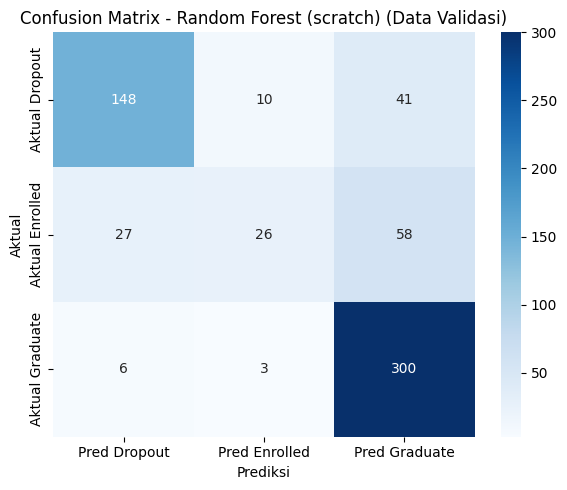

,Random Forest (scratch),Random Forest (sklearn),Selisih (scratch - sklearn)
Accuracy,0.7658,0.7851,-0.0193
Precision,0.7454,0.8021,-0.0567
Recall,0.6496,0.6673,-0.0177
F1-score,0.6577,0.6786,-0.0209


In [359]:
hasil_scratch["Random Forest"] = model_eval(y_val, pred_rf, "Random Forest (scratch)")
bandingkan(hasil_scratch["Random Forest"], "Random Forest (sklearn)")

###4.3 Evaluasi K-Nearest Neighbors

,Nilai (macro)
Accuracy,0.7593
Precision,0.7447
Recall,0.7466
F1-score,0.7309


              precision    recall  f1-score   support

     Dropout       0.91      0.67      0.77       199
    Enrolled       0.49      0.75      0.59       111
    Graduate       0.84      0.82      0.83       309

    accuracy                           0.76       619
   macro avg       0.74      0.75      0.73       619
weighted avg       0.80      0.76      0.77       619



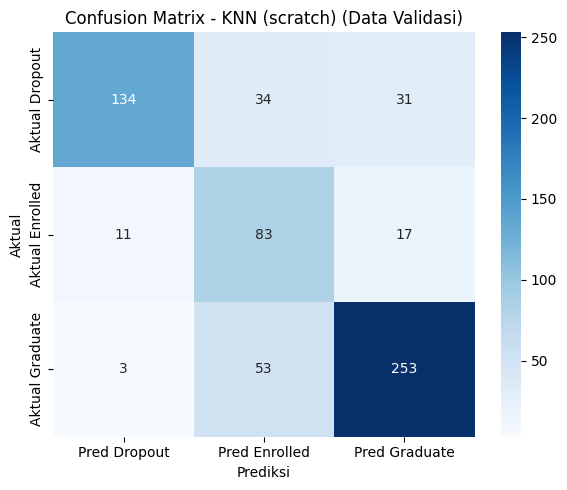

,Nilai (macro)
Accuracy,0.7593
Precision,0.7447
Recall,0.7466
F1-score,0.7309


              precision    recall  f1-score   support

     Dropout       0.91      0.67      0.77       199
    Enrolled       0.49      0.75      0.59       111
    Graduate       0.84      0.82      0.83       309

    accuracy                           0.76       619
   macro avg       0.74      0.75      0.73       619
weighted avg       0.80      0.76      0.77       619



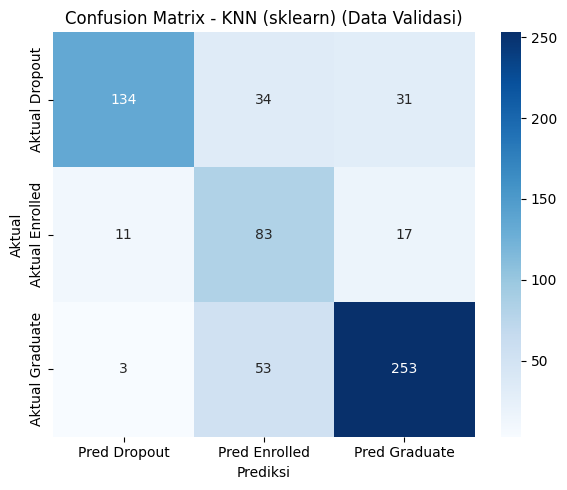

,KNN
agreement prediksi,1.000000
maks |Δ proba|,0.000000
macro-F1 scratch,0.730863
macro-F1 sklearn,0.730863
train scratch (s),0.000371
train sklearn (s),0.001172
inferensi scratch (s),0.451111
inferensi sklearn (s),0.172695


,KNN (scratch),KNN (sklearn),Selisih (scratch - sklearn)
Accuracy,0.7593,0.7593,0.0
Precision,0.7447,0.7447,0.0
Recall,0.7466,0.7466,0.0
F1-score,0.7309,0.7309,0.0


In [369]:
hasil_knn = [model_eval(y_va, pred_knn, "KNN (scratch)"), model_eval(y_va, pred_sk_knn, "KNN (sklearn)")]
hasil_sklearn.append(hasil_knn[1])


def median_time(fn, repeats=3):
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(); times.append(time.perf_counter() - t0)
    return float(np.median(times))


def compare(name, scratch_model, sk_model, X_tr_, y_tr_, X_va_, repeats=3):
    p_scratch, p_sk = scratch_model.predict_proba(X_va_), sk_model.predict_proba(X_va_)
    return pd.Series({
        "agreement prediksi": np.mean(scratch_model.predict(X_va_) == sk_model.predict(X_va_)),
        "maks |Δ proba|": np.abs(p_scratch - p_sk).max(),
        "macro-F1 scratch": sk_f1(y_va, scratch_model.predict(X_va_), average="macro"),
        "macro-F1 sklearn": sk_f1(y_va, sk_model.predict(X_va_), average="macro"),
        "train scratch (s)": median_time(lambda: type(scratch_model)(**scratch_model.get_params()).fit(X_tr_, y_tr_), repeats),
        "train sklearn (s)": median_time(lambda: __import__("sklearn").base.clone(sk_model).fit(X_tr_, y_tr_), repeats),
        "inferensi scratch (s)": median_time(lambda: scratch_model.predict(X_va_), repeats),
        "inferensi sklearn (s)": median_time(lambda: sk_model.predict(X_va_), repeats),
    }, name=name)


cmp_knn = compare("KNN", knn.model, sk_knn, Xk_tr, yk_tr, Xk_va)
display(cmp_knn.to_frame())

hasil_scratch["KNN"] = hasil_knn[0]

**Catatan**

* Hasil KNN scratch sama persis dengan scikit-learn: semua prediksi sama, dan selisih probabilitasnya 0. Preprocessing scratch juga sama dengan `buat_preprocessor()` (selisih maksimum 0,0). Jadi bedanya hanya di kecepatan.
* Di data validasi, KNN mendapat akurasi 0,759 dan macro-F1 0,731. Recall Enrolled tinggi (0,75), tapi precision-nya rendah (0,49), artinya cukup banyak mahasiswa Graduate dan Dropout yang ikut ditebak Enrolled. Ini efek dari SMOTE yang memang kami pilih untuk menaikkan macro-F1. Kelemahannya ada di recall Dropout (0,67).
* Soal waktu, `fit` KNN scratch hampir tidak butuh waktu karena hanya menyimpan data. Prediksinya beberapa kali lebih lambat dari scikit-learn, yang menghitung jarak Manhattan dengan kode yang sudah dikompilasi. Waktu prediksi KNN bertambah sebanding dengan jumlah data latih.

###4.4 Evaluasi Logistic Regression

,Nilai (macro)
Accuracy,0.7625
Precision,0.7289
Recall,0.7342
F1-score,0.7260


              precision    recall  f1-score   support

     Dropout       0.85      0.73      0.79       199
    Enrolled       0.49      0.65      0.56       111
    Graduate       0.85      0.83      0.84       309

    accuracy                           0.76       619
   macro avg       0.73      0.73      0.73       619
weighted avg       0.78      0.76      0.77       619



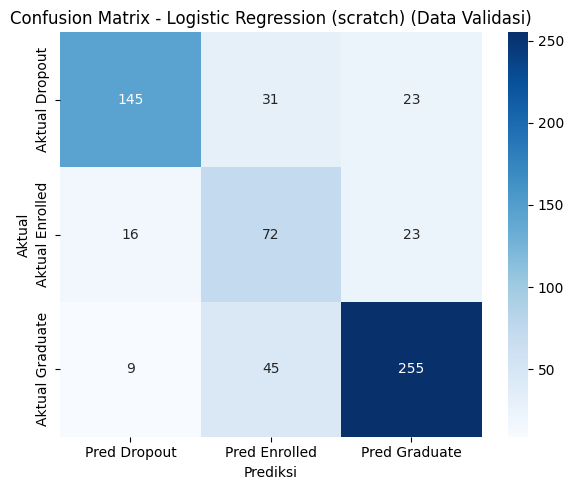

,Nilai (macro)
Accuracy,0.7625
Precision,0.7289
Recall,0.7342
F1-score,0.7260


              precision    recall  f1-score   support

     Dropout       0.85      0.73      0.79       199
    Enrolled       0.49      0.65      0.56       111
    Graduate       0.85      0.83      0.84       309

    accuracy                           0.76       619
   macro avg       0.73      0.73      0.73       619
weighted avg       0.78      0.76      0.77       619



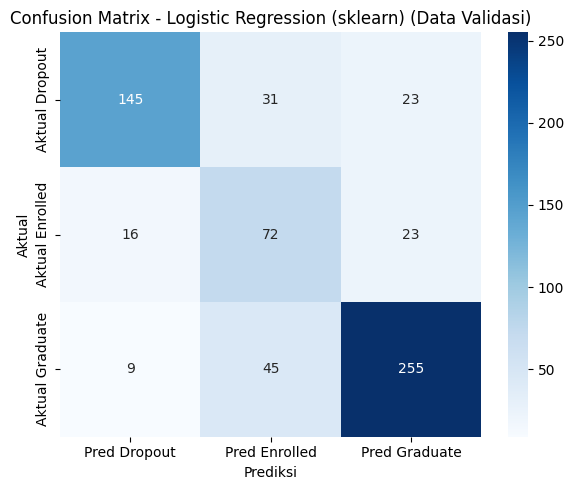

,KNN,Logistic Regression
agreement prediksi,1.0,1.000000
maks |Δ proba|,0.0,0.000426
macro-F1 scratch,0.730863,0.725986
macro-F1 sklearn,0.730863,0.725986
train scratch (s),0.000371,0.820980
train sklearn (s),0.001172,0.428564
inferensi scratch (s),0.451111,0.000284
inferensi sklearn (s),0.172695,0.001006
korelasi koefisien,-,0.999997


In [374]:
hasil_logreg = [model_eval(y_va, pred_logreg, "Logistic Regression (scratch)"), model_eval(y_va, pred_sk_logreg, "Logistic Regression (sklearn)")]
hasil_sklearn.append(hasil_logreg[1])
cmp_logreg = compare("Logistic Regression", logreg.model, sk_logreg, Xl_tr, yl_tr, Xl_va, repeats=1)
ours = logreg.model.coef_
theirs = np.column_stack([e.coef_.ravel() for e in sk_logreg.estimators_]) if LR_PARAMS["multi_class"] == "ovr" else sk_logreg.coef_.T
if LR_PARAMS["multi_class"] == "softmax":
    ours, theirs = ours - ours.mean(axis=1, keepdims=True), theirs - theirs.mean(axis=1, keepdims=True)
cmp_logreg["korelasi koefisien"] = np.corrcoef(ours.ravel(), theirs.ravel())[0, 1]
display(pd.concat([cmp_knn, cmp_logreg], axis=1).fillna("-"))

hasil_scratch["KNN"] = hasil_knn[0]
hasil_scratch["Logistic Regression"] = hasil_logreg[0]

**Catatan**

* Hasil Logistic Regression scratch sama dengan scikit-learn: prediksinya 100% sama, selisih probabilitas paling besar sekitar 4e-4, dan korelasi koefisiennya 0,999997. Keduanya meminimalkan fungsi yang sama (dan fungsi ini konveks), jadi wajar kalau hasilnya sama. Selisih kecil yang tersisa datang dari aturan berhenti yang berbeda (gradient descent kami berhenti di norma gradien 1e-4, L-BFGS punya toleransinya sendiri).
* Di data validasi, Logistic Regression mendapat akurasi 0,763 dan macro-F1 0,726. Recall Dropout-nya lebih baik dari KNN (0,73 dibanding 0,67), tapi recall Enrolled-nya lebih rendah (0,65 dibanding 0,75).
* Soal waktu, training versi scratch lebih lambat karena butuh ratusan iterasi gradient descent, sedangkan L-BFGS memakai informasi kelengkungan sehingga lebih cepat sampai. Prediksinya justru cepat, karena hanya satu perkalian matriks.
* Dibanding model anggota lain, ANN (bagian 2.5 dan 4.5) punya akurasi validasi lebih tinggi (0,80 sampai 0,82), tapi recall Enrolled-nya hanya sekitar 0,44 sampai 0,45. KNN dan Logistic Regression di sini sengaja mengorbankan sedikit akurasi untuk menaikkan recall Enrolled (0,65 sampai 0,75). Karena kesalahan yang dibuat berbeda, keduanya berguna kalau digabung dalam ensemble. Kalau leaderboard Kaggle menilai akurasi, konfigurasi tanpa penanganan ketidakseimbangan (akurasi CV 0,757) lebih cocok dipakai.

###4.5 Evaluasi Artificial Neural Network (ANN)

,Nilai (macro)
Accuracy,0.7997
Precision,0.7637
Recall,0.7220
F1-score,0.7358


              precision    recall  f1-score   support

     Dropout       0.86      0.77      0.81       199
    Enrolled       0.62      0.45      0.52       111
    Graduate       0.81      0.94      0.87       309

    accuracy                           0.80       619
   macro avg       0.76      0.72      0.74       619
weighted avg       0.79      0.80      0.79       619



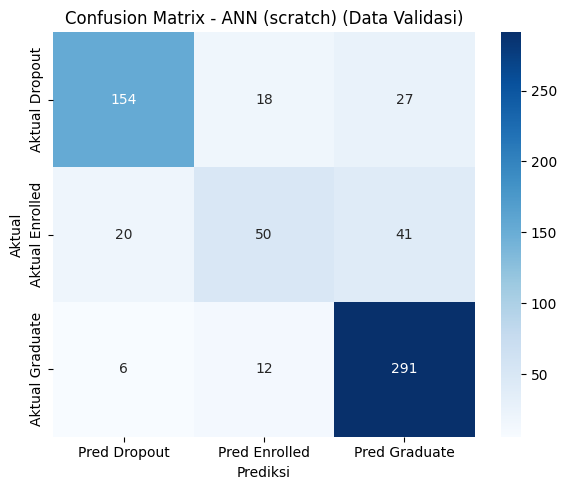

,ANN (scratch),ANN (sklearn),Selisih (scratch - sklearn)
Accuracy,0.7997,0.8158,-0.0161
Precision,0.7637,0.7941,-0.0304
Recall,0.7220,0.7339,-0.0119
F1-score,0.7358,0.7508,-0.0150


In [362]:
hasil_scratch["ANN"] = model_eval(y_val, pred_ann, "ANN (scratch)")
bandingkan(hasil_scratch["ANN"], "ANN (sklearn)")

###4.6 Evaluasi Ensembele

,Nilai (macro)
Accuracy,0.8029
Precision,0.7683
Recall,0.7418
F1-score,0.7517


              precision    recall  f1-score   support

     Dropout       0.88      0.74      0.80       199
    Enrolled       0.60      0.55      0.58       111
    Graduate       0.83      0.93      0.88       309

    accuracy                           0.80       619
   macro avg       0.77      0.74      0.75       619
weighted avg       0.80      0.80      0.80       619



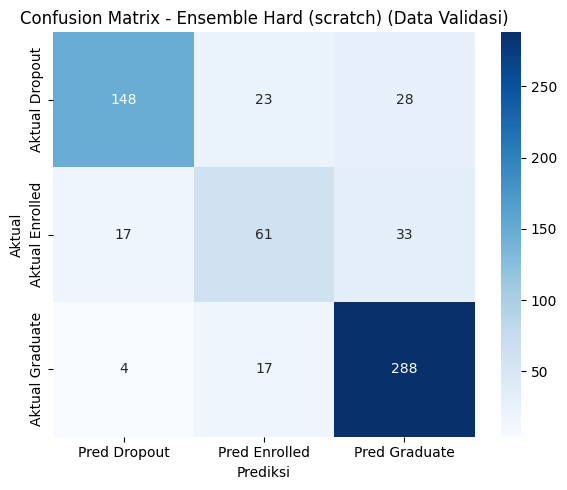

,Ensemble Hard (scratch),Ensemble Majority (sklearn),Selisih (scratch - sklearn)
Accuracy,0.8029,0.8061,-0.0032
Precision,0.7683,0.7938,-0.0255
Recall,0.7418,0.7083,0.0335
F1-score,0.7517,0.7256,0.0261


,Nilai (macro)
Accuracy,0.8061
Precision,0.7745
Recall,0.7459
F1-score,0.7565


              precision    recall  f1-score   support

     Dropout       0.89      0.74      0.81       199
    Enrolled       0.61      0.56      0.58       111
    Graduate       0.82      0.94      0.88       309

    accuracy                           0.81       619
   macro avg       0.77      0.75      0.76       619
weighted avg       0.81      0.81      0.80       619



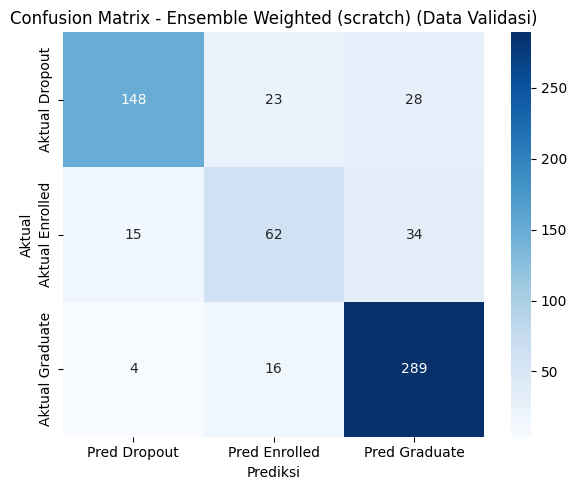

,Ensemble Weighted (scratch),Ensemble Weighted (sklearn),Selisih (scratch - sklearn)
Accuracy,0.8061,0.8061,0.0000
Precision,0.7745,0.7922,-0.0177
Recall,0.7459,0.7096,0.0363
F1-score,0.7565,0.7274,0.0291


,Nilai (macro)
Accuracy,0.7787
Precision,0.7430
Recall,0.6865
F1-score,0.7010


              precision    recall  f1-score   support

     Dropout       0.84      0.74      0.78       199
    Enrolled       0.61      0.37      0.46       111
    Graduate       0.78      0.95      0.86       309

    accuracy                           0.78       619
   macro avg       0.74      0.69      0.70       619
weighted avg       0.77      0.78      0.76       619



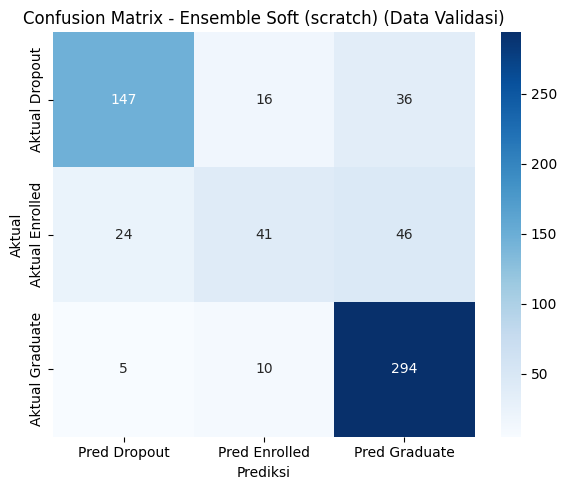

,Ensemble Soft (scratch),Ensemble Soft (sklearn),Selisih (scratch - sklearn)
Accuracy,0.7787,0.8142,-0.0355
Precision,0.7430,0.8057,-0.0627
Recall,0.6865,0.7206,-0.0341
F1-score,0.7010,0.7400,-0.0390


In [363]:
hasil_scratch["Ensemble Hard"] = model_eval(y_val, pred_hard, "Ensemble Hard (scratch)")
bandingkan(hasil_scratch["Ensemble Hard"], "Ensemble Majority (sklearn)")

hasil_scratch["Ensemble Weighted"] = model_eval(y_val, pred_weighted, "Ensemble Weighted (scratch)")
bandingkan(hasil_scratch["Ensemble Weighted"], "Ensemble Weighted (sklearn)")

hasil_scratch["Ensemble Soft"] = model_eval(y_val, pred_soft, "Ensemble Soft (scratch)")
bandingkan(hasil_scratch["Ensemble Soft"], "Ensemble Soft (sklearn)")

##5. Save & Load
Menyimpan data implementasi model

###6. Export data Prediction

In [367]:
import os

FOLDER_PRED = "predictions"
os.makedirs(FOLDER_PRED, exist_ok=True)

LABEL = {0: "Dropout", 1: "Enrolled", 2: "Graduate"}
x_test = test[x_train.columns]
id_test = test["Student_ID"]
print("Data test:", x_test.shape)

semua_prediksi = pd.DataFrame({"Student_ID": id_test})

def export_prediksi(model, nama, x_input=x_test):
    pred = np.asarray(model.predict(x_input)).astype(int)
    label = pd.Series(pred).map(LABEL)

    submission = pd.DataFrame({"Student_ID": id_test.values, "Target": label.values})
    path = os.path.join(FOLDER_PRED, f"prediksi_{nama}.csv")
    submission.to_csv(path, index=False)

    semua_prediksi[nama] = label.values
    print(f"{nama:<15} -> {path}  |  {label.value_counts().to_dict()}")


export_prediksi(dtl, "dtl")
export_prediksi(rf,  "rf")
export_prediksi(knn,    "knn")
export_prediksi(logreg, "logreg")
export_prediksi(ann, "ann")



ANGKA = {"Dropout": 0, "Enrolled": 1, "Graduate": 2}
nama_model = ["dtl", "rf", "knn", "logreg", "ann"]

pred_test = []
for nama in nama_model:
    df = pd.read_csv(f"predictions/prediksi_{nama}.csv")
    pred_test.append(df["Target"].map(ANGKA).to_numpy())
pred_test = np.array(pred_test)

ens_hard = hard_voting(pred_test)
ens_weighted = weighted_voting(pred_test, bobot)

id_test = pd.read_csv("predictions/prediksi_dtl.csv")["Student_ID"]
pd.DataFrame({"Student_ID": id_test, "Target": pd.Series(ens_hard).map(LABEL)}).to_csv("predictions/prediksi_ens_hard.csv", index=False)
pd.DataFrame({"Student_ID": id_test, "Target": pd.Series(ens_weighted).map(LABEL)}).to_csv("predictions/prediksi_ens_weighted.csv", index=False)




Data test: (1328, 18)
dtl             -> predictions/prediksi_dtl.csv  |  {'Graduate': 776, 'Dropout': 362, 'Enrolled': 190}
rf              -> predictions/prediksi_rf.csv  |  {'Graduate': 841, 'Dropout': 389, 'Enrolled': 98}
knn             -> predictions/prediksi_knn.csv  |  {'Graduate': 627, 'Enrolled': 406, 'Dropout': 295}
logreg          -> predictions/prediksi_logreg.csv  |  {'Graduate': 633, 'Dropout': 357, 'Enrolled': 338}
ann             -> predictions/prediksi_ann.csv  |  {'Graduate': 747, 'Dropout': 397, 'Enrolled': 184}


In [375]:
from google.colab import files
files.download("predictions/prediksi_dtl.csv")
files.download("predictions/prediksi_rf.csv")
files.download("predictions/prediksi_knn.csv")
files.download("predictions/prediksi_logreg.csv")
files.download("predictions/prediksi_ann.csv")



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [376]:
import os
import zipfile
from google.colab import files

nama_zip = "hasil_project2.zip"
folder_list = ["predictions", "predictions_val", "saved_models"]

with zipfile.ZipFile(nama_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in folder_list:
        if not os.path.exists(folder):
            continue
        for root, _, file_list in os.walk(folder):
            for f in file_list:
                path = os.path.join(root, f)
                z.write(path)
                print("Masuk zip:", path)

files.download(nama_zip)

Masuk zip: predictions/prediksi_ens_weighted.csv
Masuk zip: predictions/prediksi_knn.csv
Masuk zip: predictions/prediksi_rf.csv
Masuk zip: predictions/prediksi_logreg.csv
Masuk zip: predictions/prediksi_ann.csv
Masuk zip: predictions/prediksi_dtl.csv
Masuk zip: predictions/prediksi_ens_hard.csv
Masuk zip: saved_models/logreg_scratch.pkl
Masuk zip: saved_models/rf.pkl
Masuk zip: saved_models/ann.pkl
Masuk zip: saved_models/knn_scratch.pkl
Masuk zip: saved_models/dtl.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>